In [1]:
# ============================================================
# CELL 1 — Imports
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import FunctionTransformer

df_raw = pd.read_csv('../data/daily_injury_data.csv')
print(df_raw.shape)
df_raw.head(3)

(42766, 73)


,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,perceived exertion,perceived trainingSuccess,perceived recovery,...,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6,perceived exertion.6,perceived trainingSuccess.6,perceived recovery.6,Athlete ID,injury,Date
0,1.0,5.8,0.0,0.6,1.2,0.0,0.0,0.11,0.00,0.18,...,0.0,0.0,0.0,1.0,0.10,0.00,0.15,0,0,0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.01,-0.01,-0.01,...,0.5,1.2,0.0,0.0,0.10,0.00,0.17,0,0,1
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.10,0.00,0.17,...,0.0,0.0,0.0,0.0,-0.01,-0.01,-0.01,0,0,2


In [2]:
# ============================================================
# CELL 2 — Understand the structure
# ============================================================
# The dataset has a 7-day sliding window.
# Suffix .1 = yesterday, .2 = 2 days ago, ..., .6 = 6 days ago
# No suffix = today (day 0)
# 10 base features × 7 days = 70 features + Athlete ID + Date + injury

BASE_FEATURES = [
    'nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2',
    'km sprinting', 'strength training', 'hours alternative',
    'perceived exertion', 'perceived trainingSuccess', 'perceived recovery'
]

# Separate feature types
OBJECTIVE_BASE = ['nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2',
                  'km sprinting', 'strength training', 'hours alternative']

SUBJECTIVE_BASE = ['perceived exertion', 'perceived trainingSuccess', 'perceived recovery']

# Build full column lists across all 7 days
def get_all_day_cols(base_name):
    cols = [base_name]  # day 0
    cols += [f'{base_name}.{i}' for i in range(1, 7)]  # days 1-6
    return cols

# Columns that need log transform (continuous, wide range, zero-inflated)
LOG_COLS = []
for feat in ['total km', 'km Z3-4', 'km Z5-T1-T2', 'km sprinting', 'hours alternative']:
    LOG_COLS += get_all_day_cols(feat)

# Columns already on [0,1] or binary — leave as-is (after sentinel handling)
LEAVE_AS_IS = []
for feat in ['nr. sessions', 'strength training'] + SUBJECTIVE_BASE:
    LEAVE_AS_IS += get_all_day_cols(feat)

print(f'Columns to log-transform: {len(LOG_COLS)}')
print(f'Columns to leave as-is: {len(LEAVE_AS_IS)}')

Columns to log-transform: 35
Columns to leave as-is: 35


In [3]:
# ============================================================
# CELL 3 — Handle the -0.01 sentinel values
# ============================================================
# -0.01 appears ONLY in subjective columns and means "rest day, no data"
# Strategy: replace with NaN, then fill with 0
# Rationale: on a rest day, perceived exertion = 0 is semantically correct.
# We do NOT drop these rows — they represent 26.8% of data and carry
# meaningful signal (rest days matter for injury prediction).

df = df_raw.copy()

subjective_all_cols = []
for feat in SUBJECTIVE_BASE:
    subjective_all_cols += get_all_day_cols(feat)

# Replace -0.01 with 0 (rest day = no exertion, no recovery score needed)
for col in subjective_all_cols:
    df[col] = df[col].replace(-0.01, 0)

# Verify no more sentinels
assert (df[subjective_all_cols] == -0.01).sum().sum() == 0
print("Sentinel values replaced. Shape:", df.shape)

Sentinel values replaced. Shape: (42766, 73)


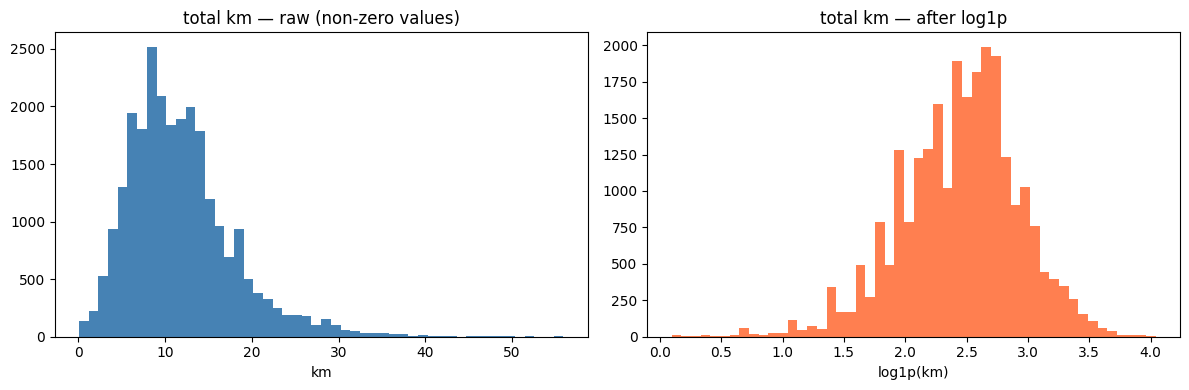

Log transform applied.
Sample values after transform (total km, non-zero):
count    25459.000
mean         2.439
std          0.489
min          0.095
25%          2.140
50%          2.485
75%          2.760
max          4.041
Name: total km, dtype: float64


In [4]:
# ============================================================
# CELL 4 — Log transform the physical load columns
# ============================================================
# Why log1p (not log)?
#   log1p(x) = log(1 + x), so log1p(0) = 0 exactly.
#   This preserves the zero = rest day meaning.
#   It compresses the long tail (55 km day) without distorting small values.

# Before/after comparison for one column
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_nonzero = df[df['total km'] > 0]['total km']
axes[0].hist(df_nonzero, bins=50, color='steelblue')
axes[0].set_title('total km — raw (non-zero values)')
axes[0].set_xlabel('km')
axes[1].hist(np.log1p(df_nonzero), bins=50, color='coral')
axes[1].set_title('total km — after log1p')
axes[1].set_xlabel('log1p(km)')
plt.tight_layout()
plt.show()

# Apply log1p to all physical load columns
df_processed = df.copy()
for col in LOG_COLS:
    df_processed[col] = np.log1p(df_processed[col])

print("Log transform applied.")
print("Sample values after transform (total km, non-zero):")
print(df_processed[df_processed['total km'] > 0]['total km'].describe().round(3))

In [5]:
# ============================================================
# CELL 6 — Drop ID and Date before modeling, save processed df
# ============================================================
# Keep Athlete ID for now (needed for group split), 
# but it will be dropped before training.

feature_cols = LOG_COLS + LEAVE_AS_IS  # 70 features
print(f"Total features: {len(feature_cols)}")
print(f"Total rows: {len(df_processed)}")

# Quick sanity check — value ranges after processing
print("\nValue ranges after full preprocessing:")
for col in BASE_FEATURES:
    vals = df_processed[col]
    print(f"  {col}: [{vals.min():.3f}, {vals.max():.3f}], mean={vals.mean():.3f}")

Total features: 70
Total rows: 42766

Value ranges after full preprocessing:
  nr. sessions: [0.000, 2.000], mean=0.830
  total km: [0.000, 4.041], mean=1.452
  km Z3-4: [0.000, 3.766], mean=0.206
  km Z5-T1-T2: [0.000, 3.892], mean=0.206
  km sprinting: [0.000, 3.714], mean=0.043
  strength training: [0.000, 2.000], mean=0.116
  hours alternative: [0.000, 2.418], mean=0.097
  perceived exertion: [0.000, 1.000], mean=0.250
  perceived trainingSuccess: [0.000, 1.000], mean=0.352
  perceived recovery: [0.000, 1.000], mean=0.199


In [6]:
# ============================================================
# CELL 7 — Revised Train/Test split
# ============================================================
from sklearn.model_selection import train_test_split

# Use raw 'injury' column as target (not Risk_Zone)
# More honest for feature importance analysis — we want patterns
# on days that actually resulted in injury, not estimated risk windows.

athletes_injured  = df_processed.groupby('Athlete ID')['injury'].sum()
athletes_with_inj = athletes_injured[athletes_injured > 0].index.tolist()
athletes_no_inj   = athletes_injured[athletes_injured == 0].index.tolist()

train_inj, test_inj = train_test_split(athletes_with_inj, test_size=0.2, random_state=42)
train_healthy, test_healthy = train_test_split(athletes_no_inj, test_size=0.2, random_state=42)

train_athletes = train_inj + train_healthy
test_athletes  = test_inj  + test_healthy

df_train = df_processed[df_processed['Athlete ID'].isin(train_athletes)].copy()
df_test  = df_processed[df_processed['Athlete ID'].isin(test_athletes)].copy()

X_train = df_train[feature_cols]
y_train = df_train['injury']
X_test  = df_test[feature_cols]
y_test  = df_test['injury']

print(f"Train: {len(df_train):,} rows | {y_train.sum()} injury days ({y_train.mean():.2%})")
print(f"Test:  {len(df_test):,} rows  | {y_test.sum()} injury days  ({y_test.mean():.2%})")
print(f"\nTrain athletes: {len(train_athletes)} | Test athletes: {len(test_athletes)}")

Train: 35,022 rows | 436 injury days (1.24%)
Test:  7,744 rows  | 147 injury days  (1.90%)

Train athletes: 58 | Test athletes: 16


In [7]:
# ============================================================
# CELL 8 — Per-athlete summary table (the missing descriptive analysis)
# ============================================================

athlete_profile = df_processed.groupby('Athlete ID').agg(
    total_days        = ('injury', 'count'),
    injury_days       = ('injury', 'sum'),
    # Use raw df for these (before log transform) for interpretability
).reset_index()

# Add features from raw df for readable summaries
raw_agg = df_raw.groupby('Athlete ID').agg(
    avg_km_per_day    = ('total km',          lambda x: x[x > 0].mean()),
    avg_sessions      = ('nr. sessions',      lambda x: x[x > 0].mean()),
    pct_rest_days     = ('nr. sessions',      lambda x: (x == 0).mean()),
    pct_strength      = ('strength training', lambda x: (x > 0).mean()),
    avg_exertion      = ('perceived exertion',lambda x: x[x > 0].mean()),
    avg_recovery      = ('perceived recovery',lambda x: x[x > 0].mean()),
).reset_index()

athlete_profile = athlete_profile.merge(raw_agg, on='Athlete ID')
athlete_profile['injury_rate']      = athlete_profile['injury_days'] / athlete_profile['total_days']
athlete_profile['training_days']    = (athlete_profile['total_days'] * 
                                       (1 - athlete_profile['pct_rest_days'])).astype(int)
# Sessions per week proxy (avg active days × 7 / total days)
athlete_profile['active_days_week'] = (1 - athlete_profile['pct_rest_days']) * 7

print(athlete_profile[['Athlete ID','total_days','injury_days','injury_rate',
                        'avg_km_per_day','active_days_week']].to_string())

    Athlete ID  total_days  injury_days  injury_rate  avg_km_per_day  active_days_week
0            0         310            7     0.022581        8.225000          3.929032
1            1         461            2     0.004338       23.673786          4.691974
2            2        1291            4     0.003098       15.454450          5.226956
3            3         344            3     0.008721        9.419433          5.290698
4            4         681            7     0.010279       15.104822          5.427313
5            5         215            1     0.004651        7.426506          4.395349
6            6         534            4     0.007491        9.299571          5.112360
7            7         304            5     0.016447       11.283750          6.286184
8            8         268            7     0.026119       10.572785          5.641791
9            9        1233           23     0.018654       10.930044          5.268451
10          10         387           10    

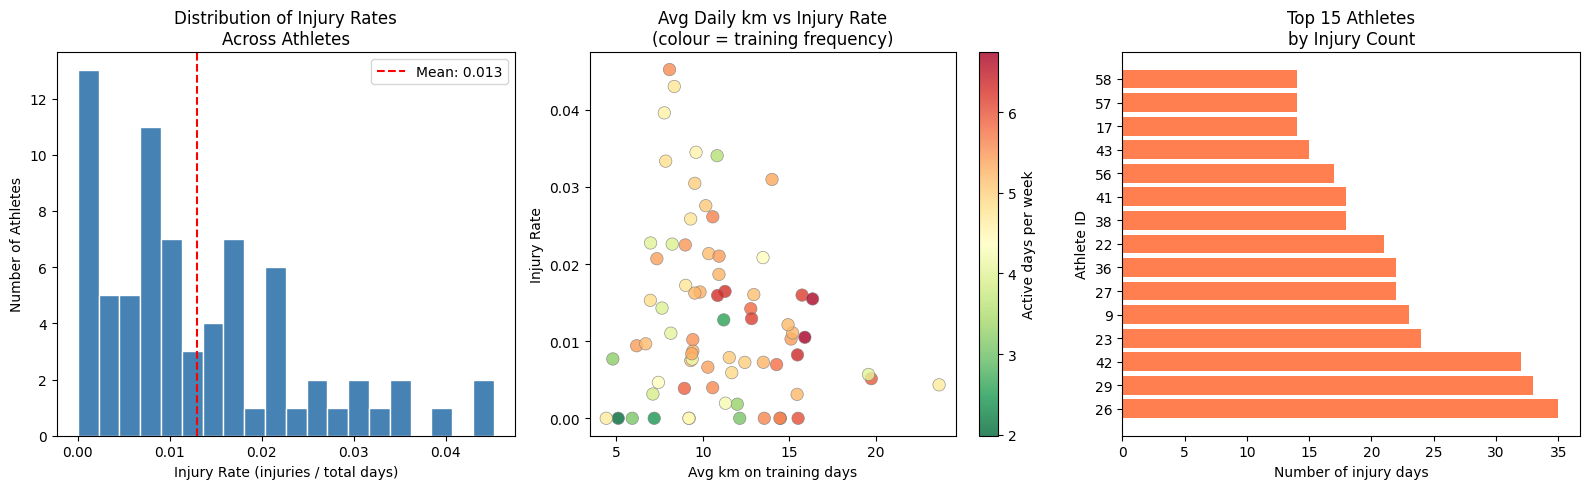

Saved fig1_athlete_eda.png


In [8]:
# ============================================================
# CELL 9 — Figure 1: Injury rate distribution across athletes
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Injury rate histogram
axes[0].hist(athlete_profile['injury_rate'], bins=20, color='steelblue', edgecolor='white')
axes[0].axvline(athlete_profile['injury_rate'].mean(), color='red', 
                linestyle='--', label=f"Mean: {athlete_profile['injury_rate'].mean():.3f}")
axes[0].set_title('Distribution of Injury Rates\nAcross Athletes')
axes[0].set_xlabel('Injury Rate (injuries / total days)')
axes[0].set_ylabel('Number of Athletes')
axes[0].legend()

# Plot 2: Avg km vs injury rate
scatter = axes[1].scatter(
    athlete_profile['avg_km_per_day'],
    athlete_profile['injury_rate'],
    c=athlete_profile['active_days_week'],
    cmap='RdYlGn_r',
    s=80, alpha=0.8, edgecolors='grey', linewidth=0.5
)
plt.colorbar(scatter, ax=axes[1], label='Active days per week')
axes[1].set_title('Avg Daily km vs Injury Rate\n(colour = training frequency)')
axes[1].set_xlabel('Avg km on training days')
axes[1].set_ylabel('Injury Rate')

# Plot 3: Top 15 athletes by injury count
top_injured = athlete_profile.nlargest(15, 'injury_days')
axes[2].barh(top_injured['Athlete ID'].astype(str), 
             top_injured['injury_days'], color='coral')
axes[2].set_title('Top 15 Athletes\nby Injury Count')
axes[2].set_xlabel('Number of injury days')
axes[2].set_ylabel('Athlete ID')

plt.tight_layout()
plt.savefig('fig1_athlete_eda.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved fig1_athlete_eda.png")

Frequency group counts:
freq_group
<3 days/week      4
3–5 days/week    28
6–7 days/week    42
Name: count, dtype: int64

Injury rate by group:
                 mean  median     std  count
freq_group                                  
<3 days/week   0.0049  0.0034  0.0062      4
3–5 days/week  0.0137  0.0077  0.0134     28
6–7 days/week  0.0132  0.0108  0.0095     42

Kruskal-Wallis test: H=3.258, p=0.1961
→ No significant difference between groups (p ≥ 0.05)
  Interpretation: training frequency alone does not explain injury rate variation.


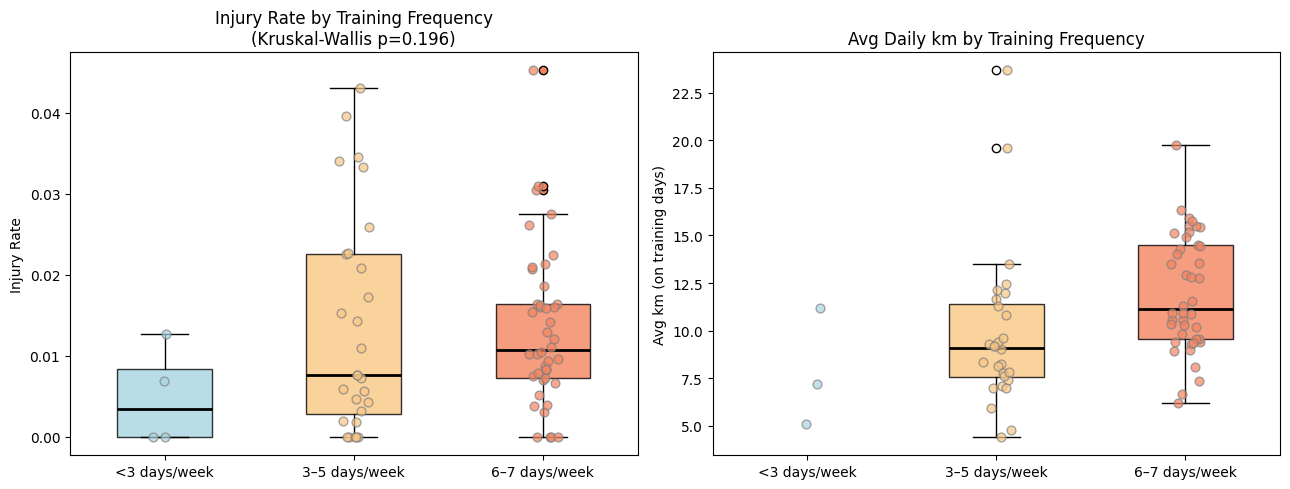

In [9]:
# ============================================================
# CELL 10 — Revised: Three frequency subgroups + statistical test
# ============================================================
from scipy import stats

athlete_profile['freq_group'] = pd.cut(
    athlete_profile['active_days_week'],
    bins=[0, 3, 5, 7.1],
    labels=['<3 days/week', '3–5 days/week', '6–7 days/week']
)

print("Frequency group counts:")
print(athlete_profile['freq_group'].value_counts().sort_index())
print()
print("Injury rate by group:")
print(athlete_profile.groupby('freq_group', observed=True)['injury_rate']
      .agg(['mean', 'median', 'std', 'count']).round(4))

# Kruskal-Wallis test (non-parametric, doesn't assume normality)
# Tests whether the groups have different injury rate distributions
g1 = athlete_profile[athlete_profile['freq_group']=='<3 days/week']['injury_rate']
g2 = athlete_profile[athlete_profile['freq_group']=='3–5 days/week']['injury_rate']
g3 = athlete_profile[athlete_profile['freq_group']=='6–7 days/week']['injury_rate']

stat, p = stats.kruskal(g1, g2, g3)
print(f"\nKruskal-Wallis test: H={stat:.3f}, p={p:.4f}")
if p < 0.05:
    print("→ Significant difference in injury rates between frequency groups (p < 0.05)")
else:
    print("→ No significant difference between groups (p ≥ 0.05)")
    print("  Interpretation: training frequency alone does not explain injury rate variation.")

# Plot — three groups now
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

groups_data = [g1, g2, g3]
group_labels = ['<3 days/week', '3–5 days/week', '6–7 days/week']
colors = ['#a8d5e2', '#f9c784', '#f4845f']

# Boxplot with individual points overlaid
for i, (g, label, color) in enumerate(zip(groups_data, group_labels, colors)):
    bp = axes[0].boxplot(g, positions=[i], widths=0.5, patch_artist=True,
                         boxprops=dict(facecolor=color, alpha=0.8),
                         medianprops=dict(color='black', linewidth=2),
                         flierprops=dict(marker='o', markerfacecolor=color))
    # Overlay individual points (jittered)
    jitter = np.random.uniform(-0.08, 0.08, size=len(g))
    axes[0].scatter([i + j for j in jitter], g, 
                    color=color, edgecolors='grey', s=40, zorder=5, alpha=0.7)

axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(group_labels)
axes[0].set_title(f'Injury Rate by Training Frequency\n(Kruskal-Wallis p={p:.3f})')
axes[0].set_ylabel('Injury Rate')

# Avg km by group
km_groups = [
    athlete_profile[athlete_profile['freq_group']==l]['avg_km_per_day'] 
    for l in group_labels
]
for i, (g, label, color) in enumerate(zip(km_groups, group_labels, colors)):
    axes[1].boxplot(g, positions=[i], widths=0.5, patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.8),
                    medianprops=dict(color='black', linewidth=2))
    jitter = np.random.uniform(-0.08, 0.08, size=len(g))
    axes[1].scatter([i + j for j in jitter], g,
                    color=color, edgecolors='grey', s=40, zorder=5, alpha=0.7)

axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(group_labels)
axes[1].set_title('Avg Daily km by Training Frequency')
axes[1].set_ylabel('Avg km (on training days)')

plt.tight_layout()
plt.savefig('fig2_frequency_groups.png', dpi=150, bbox_inches='tight')
plt.show()

Athletes available for clustering: 73

Missing values:
avg_km_per_day      0
active_days_week    0
avg_exertion        0
avg_recovery        0
pct_rest_days       0
pct_strength        0
dtype: int64


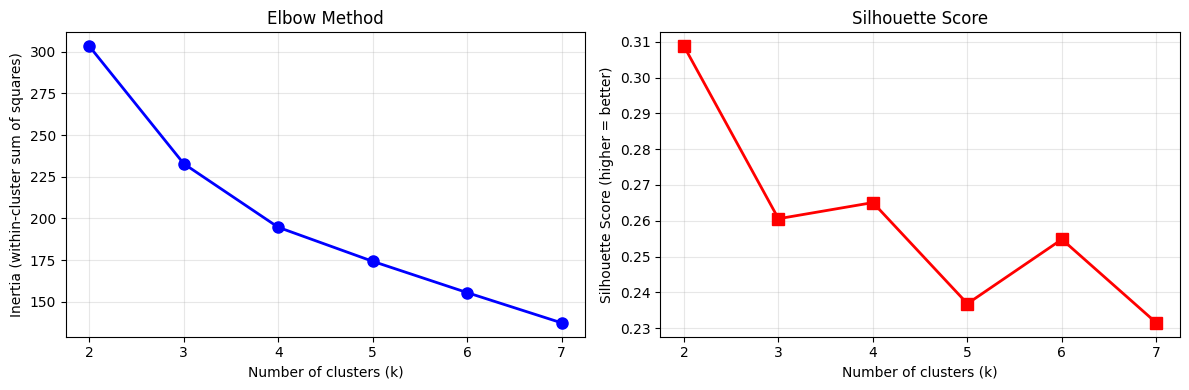


Silhouette scores:
  k=2: 0.3088
  k=3: 0.2606
  k=4: 0.2651
  k=5: 0.2368
  k=6: 0.2548
  k=7: 0.2315


In [10]:
# ============================================================
# CELL 11 — K-Means clustering on athlete profiles
# ============================================================
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# For clustering we use PER-ATHLETE aggregate features (raw values, interpretable)
# We cluster athletes, not individual training days
# Features: volume, intensity mix, frequency, perceived wellness

cluster_features = athlete_profile[[
    'avg_km_per_day',       # volume
    'active_days_week',     # frequency  
    'avg_exertion',         # perceived effort
    'avg_recovery',         # perceived recovery
    'pct_rest_days',        # rest behavior
    'pct_strength',         # cross-training
]].copy()

# Drop athletes with NaN (athlete 44 has NaN avg_km — trains 0 km apparently)
cluster_features = cluster_features.dropna()
valid_athletes = cluster_features.index  # keep track

print(f"Athletes available for clustering: {len(cluster_features)}")
print("\nMissing values:")
print(cluster_features.isnull().sum())

# Standardize for clustering (here we DO use StandardScaler
# because we're comparing features with very different units:
# km vs proportions vs days/week)
scaler = StandardScaler()
X_cluster = scaler.fit_transform(cluster_features)

# --- Elbow + Silhouette to choose k ---
inertias = []
silhouettes = []
K_range = range(2, 8)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia (within-cluster sum of squares)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, silhouettes, 'rs-', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score (higher = better)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig3_kmeans_selection.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nSilhouette scores:")
for k, s in zip(K_range, silhouettes):
    print(f"  k={k}: {s:.4f}")

Cluster profiles:
         n_athletes   avg_km  avg_freq  avg_exertion  avg_recovery  avg_rest_pct  avg_injury_rate  median_injury_rate
cluster                                                                                                              
0                20   8.3838    3.7496        0.2044        0.1897        0.4643           0.0089              0.0062
1                53  11.9322    5.3885        0.3634        0.2851        0.2302           0.0146              0.0121


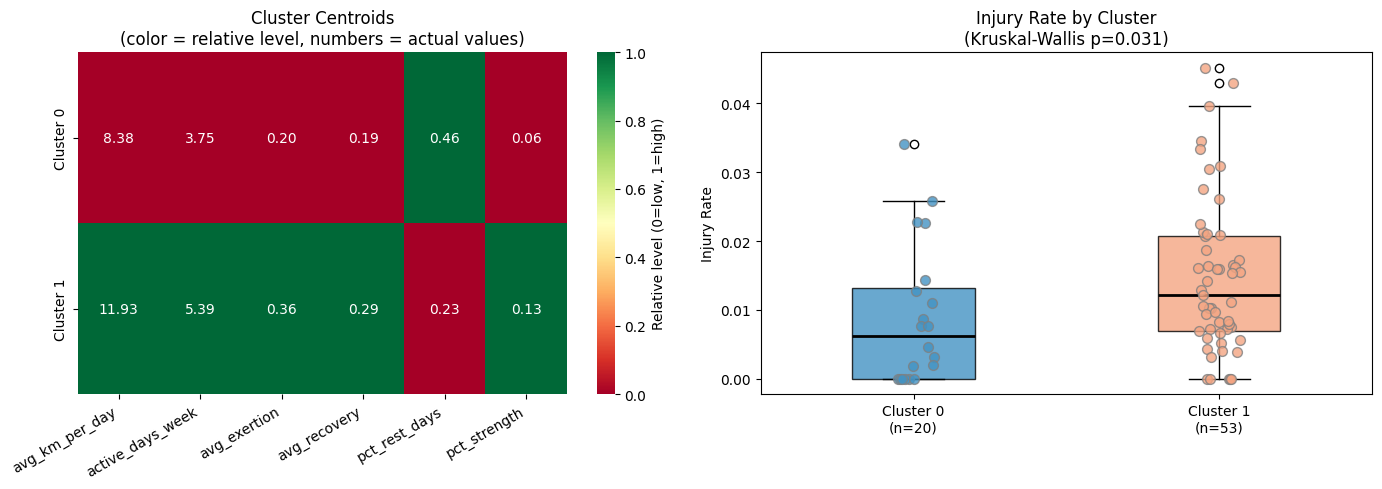

In [11]:
# ============================================================
# CELL 12 — Apply chosen k and profile the clusters
# ============================================================
# Run this after seeing the elbow/silhouette plot.
# Replace k=3 with whatever the plots suggest.

CHOSEN_K = 2  # adjust after seeing Cell 11 output

km_final = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10)
cluster_labels = km_final.fit_predict(X_cluster)

# Add cluster back to athlete_profile
athlete_profile_clustered = athlete_profile.loc[valid_athletes].copy()
athlete_profile_clustered['cluster'] = cluster_labels

# Profile each cluster — what makes them different?
cluster_profile = athlete_profile_clustered.groupby('cluster').agg(
    n_athletes        = ('Athlete ID',      'count'),
    avg_km            = ('avg_km_per_day',  'mean'),
    avg_freq          = ('active_days_week','mean'),
    avg_exertion      = ('avg_exertion',    'mean'),
    avg_recovery      = ('avg_recovery',    'mean'),
    avg_rest_pct      = ('pct_rest_days',   'mean'),
    avg_injury_rate   = ('injury_rate',     'mean'),
    median_injury_rate= ('injury_rate',     'median'),
).round(4)

print("Cluster profiles:")
print(cluster_profile.to_string())

# Visualize cluster profiles as a heatmap (normalized for comparison)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap of cluster centroids (back-transformed to original scale)
centroids_df = pd.DataFrame(
    scaler.inverse_transform(km_final.cluster_centers_),
    columns=cluster_features.columns
)
centroids_df.index = [f'Cluster {i}' for i in range(CHOSEN_K)]

# Normalize each column to [0,1] just for the heatmap display
centroids_norm = (centroids_df - centroids_df.min()) / (centroids_df.max() - centroids_df.min())
sns.heatmap(centroids_norm, annot=centroids_df.round(2), fmt='.2f',
            cmap='RdYlGn', ax=axes[0], cbar_kws={'label': 'Relative level (0=low, 1=high)'})
axes[0].set_title('Cluster Centroids\n(color = relative level, numbers = actual values)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')

# Injury rate by cluster (boxplot with points)
colors_c = ['#4393c3', '#f4a582', '#66c164']
for i in range(CHOSEN_K):
    g = athlete_profile_clustered[athlete_profile_clustered['cluster']==i]['injury_rate']
    axes[1].boxplot(g, positions=[i], widths=0.4, patch_artist=True,
                    boxprops=dict(facecolor=colors_c[i], alpha=0.8),
                    medianprops=dict(color='black', linewidth=2))
    jitter = np.random.uniform(-0.07, 0.07, size=len(g))
    axes[1].scatter([i + j for j in jitter], g,
                    color=colors_c[i], edgecolors='grey', s=50, zorder=5, alpha=0.8)

# Add Kruskal-Wallis p-value
cluster_groups = [
    athlete_profile_clustered[athlete_profile_clustered['cluster']==i]['injury_rate'].values
    for i in range(CHOSEN_K)
]
stat, p_cluster = stats.kruskal(*cluster_groups)
axes[1].set_xticks(range(CHOSEN_K))
axes[1].set_xticklabels([f'Cluster {i}\n(n={len(g)})' 
                          for i, g in enumerate(cluster_groups)])
axes[1].set_title(f'Injury Rate by Cluster\n(Kruskal-Wallis p={p_cluster:.3f})')
axes[1].set_ylabel('Injury Rate')

plt.tight_layout()
plt.savefig('fig4_cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# ============================================================
# CELL 13 — Feature importance: what predicts injury?
# ============================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE

# Add cluster labels back to the full processed dataframe
cluster_map = dict(zip(
    athlete_profile_clustered['Athlete ID'],
    athlete_profile_clustered['cluster']
))
df_processed['cluster'] = df_processed['Athlete ID'].map(cluster_map)

# Rebuild train/test with cluster info
df_train = df_processed[df_processed['Athlete ID'].isin(train_athletes)].copy()
df_test  = df_processed[df_processed['Athlete ID'].isin(test_athletes)].copy()

X_train = df_train[feature_cols]
y_train = df_train['injury']
X_test  = df_test[feature_cols]
y_test  = df_test['injury']

# Handle class imbalance with SMOTE
sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)
print(f"After SMOTE — train class distribution: {pd.Series(y_train_bal).value_counts().to_dict()}")

# Train Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_bal, y_train_bal)

# --- Built-in feature importance (MDI) ---
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

# Collapse to base feature name (average across all 7 day lags)
importance_df['base_feature'] = importance_df['feature'].str.replace(r'\.\d+$', '', regex=True)
base_importance = importance_df.groupby('base_feature')['importance'].sum().sort_values(ascending=False)

print("\nFeature importance by base feature (summed across 7 days):")
print(base_importance.round(4))

After SMOTE — train class distribution: {0: 34586, 1: 34586}

Feature importance by base feature (summed across 7 days):
base_feature
nr. sessions                 0.1952
perceived trainingSuccess    0.1699
perceived recovery           0.1139
perceived exertion           0.1111
strength training            0.1047
total km                     0.1009
km sprinting                 0.0647
km Z5-T1-T2                  0.0562
hours alternative            0.0434
km Z3-4                      0.0401
Name: importance, dtype: float64


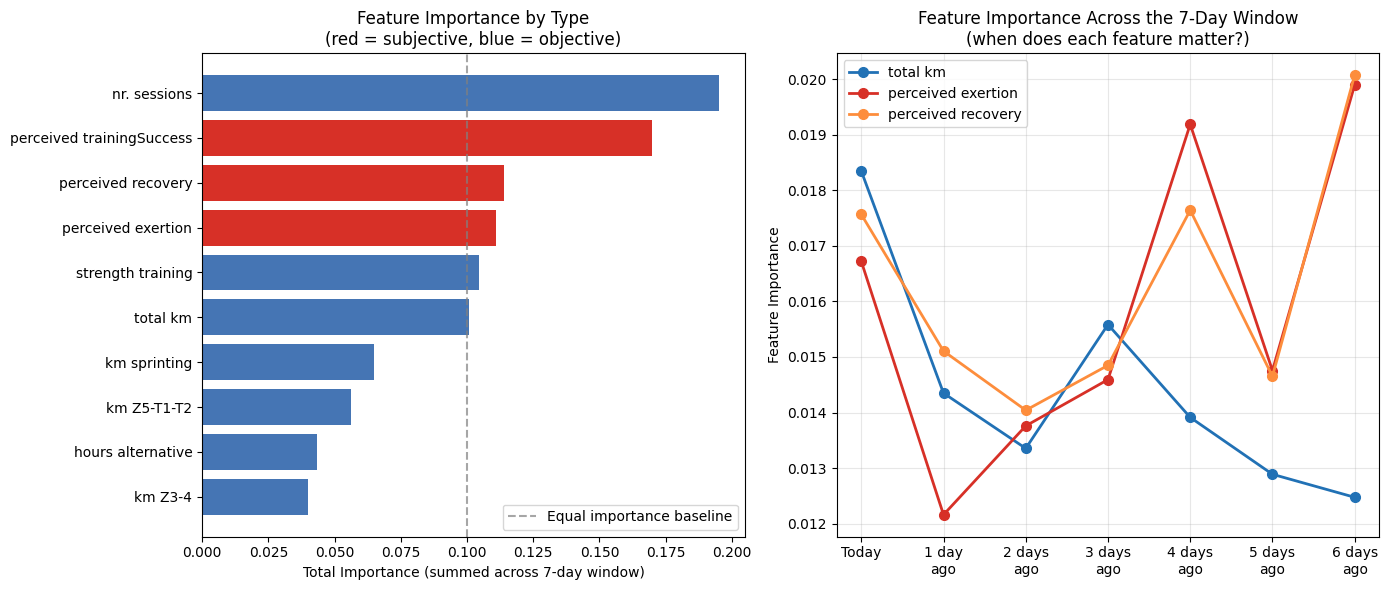

In [13]:
# ============================================================
# CELL 14 — Figure: Feature importance (global + by lag)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Base feature importance (summed across lags)
colors_feat = ['#d73027' if 'perceived' in f else '#4575b4' 
               for f in base_importance.index]
axes[0].barh(base_importance.index[::-1], base_importance.values[::-1], 
             color=colors_feat[::-1])
axes[0].set_title('Feature Importance by Type\n(red = subjective, blue = objective)')
axes[0].set_xlabel('Total Importance (summed across 7-day window)')
axes[0].axvline(x=1/len(base_importance.index), color='grey', 
                linestyle='--', alpha=0.7, label='Equal importance baseline')
axes[0].legend()

# Plot 2: Importance of 'total km' and 'perceived exertion' across lag days
# Shows WHEN in the 7-day window each feature matters most
lags_to_plot = ['total km', 'perceived exertion', 'perceived recovery']
lag_colors = ['#2171b5', '#d73027', '#fd8d3c']

for feat, color in zip(lags_to_plot, lag_colors):
    lag_cols = [feat] + [f'{feat}.{i}' for i in range(1, 7)]
    lag_imp = [importance_df[importance_df['feature']==c]['importance'].values[0] 
               for c in lag_cols]
    axes[1].plot(range(7), lag_imp, 'o-', color=color, linewidth=2, 
                 markersize=7, label=feat)

axes[1].set_xticks(range(7))
axes[1].set_xticklabels(['Today', '1 day\nago', '2 days\nago', '3 days\nago', 
                          '4 days\nago', '5 days\nago', '6 days\nago'])
axes[1].set_title('Feature Importance Across the 7-Day Window\n(when does each feature matter?)')
axes[1].set_ylabel('Feature Importance')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig5_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


Cluster 0: 4267 training rows, 37 injuries

Cluster 1: 30174 training rows, 395 injuries


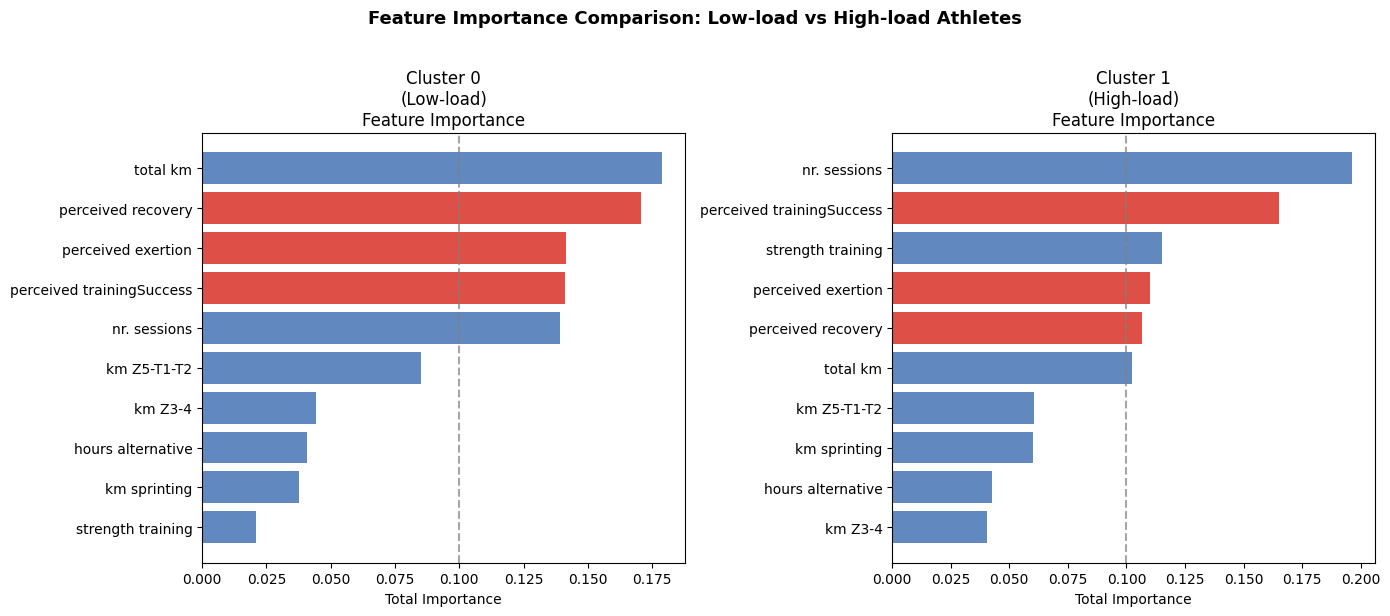

In [14]:
# ============================================================
# CELL 15 — Feature importance per cluster (does it differ?)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cluster_names = ['Cluster 0\n(Low-load)', 'Cluster 1\n(High-load)']
cluster_colors = ['#4393c3', '#f4a582']

for cluster_id, (ax, name, color) in enumerate(zip(axes, cluster_names, cluster_colors)):
    
    # Get training data for this cluster only
    mask = df_train['cluster'] == cluster_id
    X_c = df_train.loc[mask, feature_cols]
    y_c = df_train.loc[mask, 'injury']
    
    print(f"\nCluster {cluster_id}: {mask.sum()} training rows, {y_c.sum()} injuries")
    
    if y_c.sum() < 5:
        ax.text(0.5, 0.5, 'Not enough\ninjury cases', 
                ha='center', va='center', transform=ax.transAxes)
        continue
    
    # SMOTE per cluster
    sm_c = SMOTE(random_state=42)
    X_c_bal, y_c_bal = sm_c.fit_resample(X_c, y_c)
    
    rf_c = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf_c.fit(X_c_bal, y_c_bal)
    
    imp_c = pd.DataFrame({
        'feature': feature_cols,
        'importance': rf_c.feature_importances_
    })
    imp_c['base_feature'] = imp_c['feature'].str.replace(r'\.\d+$', '', regex=True)
    base_imp_c = imp_c.groupby('base_feature')['importance'].sum().sort_values(ascending=False)
    
    feat_colors = ['#d73027' if 'perceived' in f else '#4575b4' 
                   for f in base_imp_c.index]
    ax.barh(base_imp_c.index[::-1], base_imp_c.values[::-1], 
            color=feat_colors[::-1], alpha=0.85)
    ax.set_title(f'{name}\nFeature Importance')
    ax.set_xlabel('Total Importance')
    ax.axvline(x=1/len(base_imp_c.index), color='grey', linestyle='--', alpha=0.7)

plt.suptitle('Feature Importance Comparison: Low-load vs High-load Athletes', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig6_cluster_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# ============================================================
# CELL 16 — What do the days before an injury look like?
# (Injury day profiles vs healthy day profiles)
# ============================================================

# Compare average feature values on injury days vs healthy days
# Use only today's features (no suffix) for clarity

today_features = ['nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2',
                  'km sprinting', 'strength training', 'hours alternative',
                  'perceived exertion', 'perceived trainingSuccess', 'perceived recovery']

injury_days    = df_processed[df_processed['injury'] == 1][today_features]
healthy_days   = df_processed[df_processed['injury'] == 0][today_features]

comparison = pd.DataFrame({
    'Healthy days (mean)': healthy_days.mean(),
    'Injury days (mean)':  injury_days.mean(),
}).round(4)
comparison['Ratio (injury/healthy)'] = (
    comparison['Injury days (mean)'] / comparison['Healthy days (mean)']
).round(2)

print("Feature averages: healthy vs injury days")
print(comparison.to_string())

Feature averages: healthy vs injury days
                           Healthy days (mean)  Injury days (mean)  Ratio (injury/healthy)
nr. sessions                            0.8279              0.9485                    1.15
total km                                1.4485              1.7109                    1.18
km Z3-4                                 0.2057              0.2073                    1.01
km Z5-T1-T2                             0.2044              0.3196                    1.56
km sprinting                            0.0428              0.0732                    1.71
strength training                       0.1160              0.1321                    1.14
hours alternative                       0.0968              0.0763                    0.79
perceived exertion                      0.2493              0.3365                    1.35
perceived trainingSuccess               0.3510              0.4608                    1.31
perceived recovery                      0.1979   

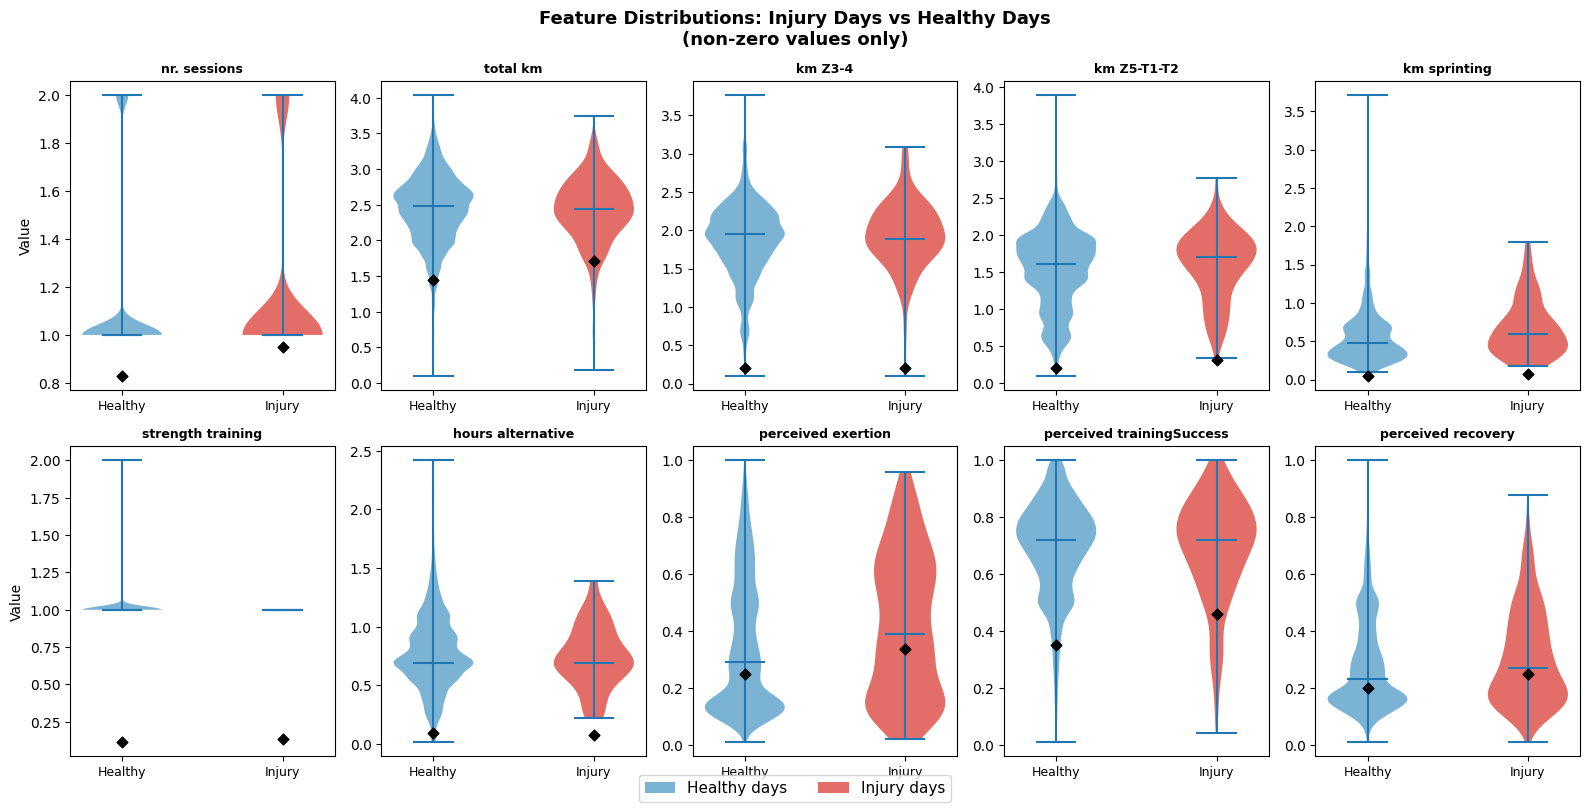

In [16]:
# ============================================================
# CELL 17 — Figure: Injury vs Healthy day profiles
# ============================================================

fig, axes = plt.subplots(2, 5, figsize=(16, 8))
axes = axes.flatten()

for i, feat in enumerate(today_features):
    ax = axes[i]
    
    healthy_vals = healthy_days[feat]
    injury_vals  = injury_days[feat]
    
    # Use violin plot to show full distribution
    parts = ax.violinplot(
        [healthy_vals[healthy_vals > 0], injury_vals[injury_vals > 0]],
        positions=[0, 1], showmedians=True
    )
    
    # Color them differently
    parts['bodies'][0].set_facecolor('#4393c3')
    parts['bodies'][0].set_alpha(0.7)
    parts['bodies'][1].set_facecolor('#d73027')
    parts['bodies'][1].set_alpha(0.7)
    
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Healthy', 'Injury'], fontsize=9)
    ax.set_title(feat, fontsize=9, fontweight='bold')
    ax.set_ylabel('Value' if i % 5 == 0 else '')
    
    # Add mean markers
    ax.scatter([0, 1], [healthy_vals.mean(), injury_vals.mean()],
               marker='D', color='black', s=30, zorder=5, label='Mean')

# Add a shared legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4393c3', alpha=0.7, label='Healthy days'),
    Patch(facecolor='#d73027', alpha=0.7, label='Injury days'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, 
           bbox_to_anchor=(0.5, -0.02), fontsize=11)

plt.suptitle('Feature Distributions: Injury Days vs Healthy Days\n(non-zero values only)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig7_injury_vs_healthy_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

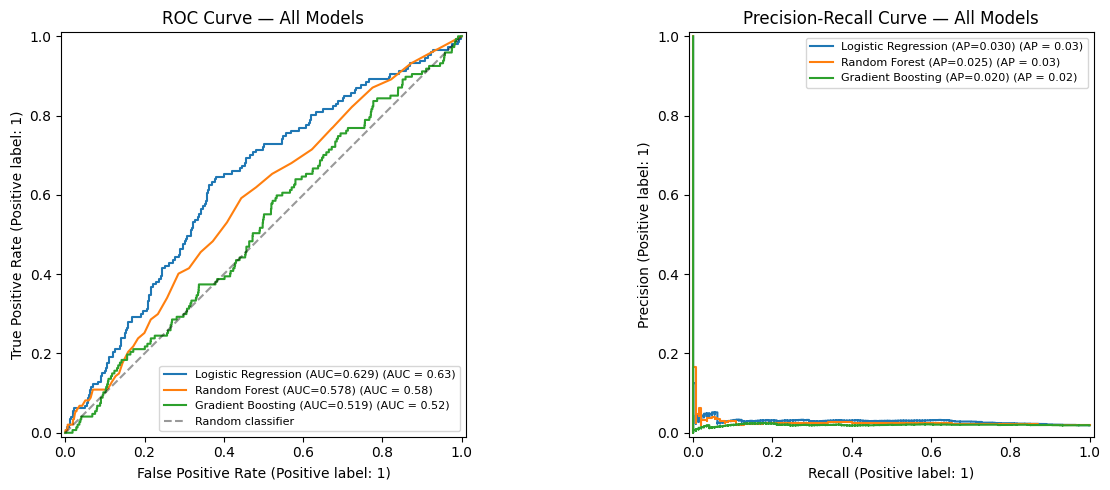


Model comparison (threshold=0.3):
                     AUC-ROC  Avg Prec  Recall  Precision     F1
Logistic Regression    0.629     0.030   0.912      0.020  0.040
Random Forest          0.578     0.025   0.020      0.049  0.029
Gradient Boosting      0.519     0.020   0.041      0.018  0.025

Note: threshold lowered from 0.5 to 0.3
Justification: in injury prediction, missing a real injury (false negative)
is more costly than an unnecessary rest day (false positive).


In [17]:
# ============================================================
# CELL 18 — Revised: Three models + threshold tuning
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, roc_auc_score,
                              RocCurveDisplay, PrecisionRecallDisplay,
                              average_precision_score)

models = {
    'Logistic Regression':    LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':          RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting':      GradientBoostingClassifier(n_estimators=200, random_state=42),
}

# Why these three?
# - Logistic Regression: linear baseline, interpretable coefficients
# - Random Forest: non-linear ensemble, robust feature importance
# - Gradient Boosting: sequential ensemble, often best on imbalanced tabular data
# All three have different inductive biases — comparing them is methodologically sound

results = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, model in models.items():
    model.fit(X_train_bal, y_train_bal)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    # Use threshold=0.3 instead of 0.5 — justified because:
    # missing an injury (false negative) is far more costly than a false alarm
    # so we accept more false positives to catch more real injuries
    THRESHOLD = 0.3
    y_pred_tuned = (y_proba >= THRESHOLD).astype(int)
    
    auc    = roc_auc_score(y_test, y_proba)
    ap     = average_precision_score(y_test, y_proba)
    report = classification_report(y_test, y_pred_tuned, output_dict=True, zero_division=0)
    
    results[name] = {
        'AUC-ROC':   round(auc, 3),
        'Avg Prec':  round(ap, 3),
        'Recall':    round(report['1']['recall'], 3),
        'Precision': round(report['1']['precision'], 3),
        'F1':        round(report['1']['f1-score'], 3),
    }
    
    RocCurveDisplay.from_predictions(
        y_test, y_proba, name=f'{name} (AUC={auc:.3f})', ax=axes[0])
    PrecisionRecallDisplay.from_predictions(
        y_test, y_proba, name=f'{name} (AP={ap:.3f})',  ax=axes[1])

axes[0].set_title('ROC Curve — All Models')
axes[0].plot([0,1],[0,1],'k--', alpha=0.4, label='Random classifier')
axes[0].legend(fontsize=8)
axes[1].set_title('Precision-Recall Curve — All Models')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig8_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

results_df = pd.DataFrame(results).T
print(f"\nModel comparison (threshold={THRESHOLD}):")
print(results_df.to_string())
print(f"\nNote: threshold lowered from 0.5 to {THRESHOLD}")
print("Justification: in injury prediction, missing a real injury (false negative)")
print("is more costly than an unnecessary rest day (false positive).")

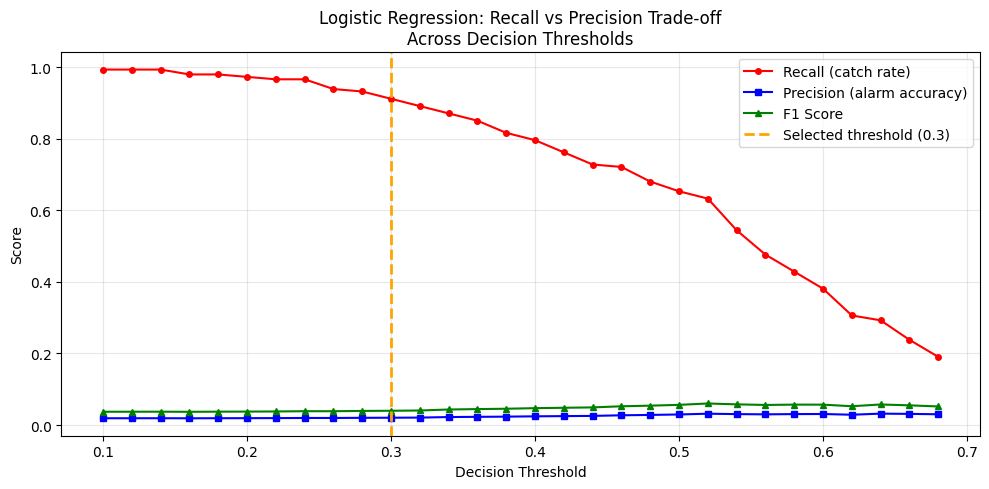

In [18]:
# ============================================================
# CELL 19 — Threshold sensitivity: what's the right cutoff?
# ============================================================
import numpy as np

# Show how recall and precision trade off across thresholds for best model
# (we'll use whichever has highest AUC after running Cell 18)

best_model = models['Logistic Regression']  # update if RF or GB wins
y_proba_best = best_model.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.1, 0.7, 0.02)
recalls, precisions, f1s = [], [], []

for t in thresholds:
    y_pred_t = (y_proba_best >= t).astype(int)
    r = classification_report(y_test, y_pred_t, output_dict=True, zero_division=0)
    recalls.append(r['1']['recall'])
    precisions.append(r['1']['precision'])
    f1s.append(r['1']['f1-score'])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, recalls,    'r-o', markersize=4, label='Recall (catch rate)')
ax.plot(thresholds, precisions, 'b-s', markersize=4, label='Precision (alarm accuracy)')
ax.plot(thresholds, f1s,        'g-^', markersize=4, label='F1 Score')
ax.axvline(x=0.3, color='orange', linestyle='--', linewidth=2, label='Selected threshold (0.3)')
ax.set_xlabel('Decision Threshold')
ax.set_ylabel('Score')
ax.set_title('Logistic Regression: Recall vs Precision Trade-off\nAcross Decision Thresholds')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig9_threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()

In [19]:
# ============================================================
# CELL 20 — Per-cluster model performance
# ============================================================
# Key question: does LR perform better on one cluster than the other?
# If yes: confirms that inter-individual variability affects predictability

from sklearn.metrics import roc_auc_score, classification_report

# Best model from Cell 18
best_model_name = 'Logistic Regression'
best_model = models[best_model_name]

print(f"Per-cluster evaluation — {best_model_name} (threshold=0.3)\n")
print(f"{'Cluster':<12} {'n_rows':<10} {'n_injuries':<12} {'AUC':>6} {'Recall':>8} {'Precision':>10}")
print("-" * 60)

for cluster_id in [0, 1]:
    cluster_label = "Low-load" if cluster_id == 0 else "High-load"
    
    mask_test = df_test['cluster'] == cluster_id
    X_c = df_test.loc[mask_test, feature_cols]
    y_c = df_test.loc[mask_test, 'injury']
    
    if y_c.sum() < 3:
        print(f"Cluster {cluster_id} ({cluster_label}): not enough injury cases in test set")
        continue
    
    y_proba_c = best_model.predict_proba(X_c)[:, 1]
    y_pred_c  = (y_proba_c >= 0.3).astype(int)
    
    auc_c    = roc_auc_score(y_c, y_proba_c)
    report_c = classification_report(y_c, y_pred_c, output_dict=True, zero_division=0)
    recall_c = report_c['1']['recall']
    prec_c   = report_c['1']['precision']
    
    print(f"Cluster {cluster_id} ({cluster_label:<10}) "
          f"{mask_test.sum():<10} {y_c.sum():<12} "
          f"{auc_c:>6.3f} {recall_c:>8.3f} {prec_c:>10.3f}")

print()
print("Global (all test athletes):")
y_proba_all = best_model.predict_proba(X_test)[:, 1]
auc_all = roc_auc_score(y_test, y_proba_all)
rep_all = classification_report(y_test, (y_proba_all>=0.3).astype(int), 
                                 output_dict=True, zero_division=0)
print(f"{'All':<22} {len(X_test):<10} {y_test.sum():<12} "
      f"{auc_all:>6.3f} {rep_all['1']['recall']:>8.3f} {rep_all['1']['precision']:>10.3f}")

Per-cluster evaluation — Logistic Regression (threshold=0.3)

Cluster      n_rows     n_injuries      AUC   Recall  Precision
------------------------------------------------------------
Cluster 0 (Low-load  ) 1380       19            0.566    0.737      0.014
Cluster 1 (High-load ) 6364       128           0.637    0.938      0.022

Global (all test athletes):
All                    7744       147           0.629    0.912      0.020


In [20]:
# ============================================================
# CELL 23 — Compare: injury target vs Risk_Zone target
#           + add SVM to the model comparison
# ============================================================
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

# --- Rebuild Risk_Zone on df_processed ---
df_processed = df_processed.sort_values(['Athlete ID', 'Date']).reset_index(drop=True)
df_processed['Risk_Zone'] = 0

for athlete_id, group in df_processed.groupby('Athlete ID'):
    injury_indices = group.index[group['injury'] == 1].tolist()
    for idx in injury_indices:
        for lookback in range(0, 4):
            target_idx = idx - lookback
            if target_idx in group.index:
                df_processed.loc[target_idx, 'Risk_Zone'] = 1

# Rebuild train/test splits for both targets
df_train = df_processed[df_processed['Athlete ID'].isin(train_athletes)].copy()
df_test  = df_processed[df_processed['Athlete ID'].isin(test_athletes)].copy()

targets = {
    'injury (raw)':   ('injury',    df_train['injury'],    df_test['injury']),
    'Risk_Zone (±3d)':('Risk_Zone', df_train['Risk_Zone'], df_test['Risk_Zone']),
}

model_definitions = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'SVM (RBF kernel)':    SVC(kernel='rbf', probability=True, random_state=42, C=1.0),
}

THRESHOLD = 0.3
all_results = []

for target_name, (target_col, y_tr_raw, y_te_raw) in targets.items():
    
    X_tr_raw = df_train[feature_cols]
    X_te_raw = df_test[feature_cols]
    
    # SMOTE balance
    sm = SMOTE(random_state=42)
    X_tr_bal, y_tr_bal = sm.fit_resample(X_tr_raw, y_tr_raw)
    
    print(f"\n{'='*55}")
    print(f"Target: {target_name}  |  "
          f"Positive rate: {y_tr_raw.mean():.2%} train / {y_te_raw.mean():.2%} test")
    print(f"{'='*55}")
    
    for model_name, model in model_definitions.items():
        
        # SVM is slow on large data — subsample SMOTE output if needed
        if 'SVM' in model_name and len(X_tr_bal) > 20000:
            idx_sample = np.random.RandomState(42).choice(
                len(X_tr_bal), 20000, replace=False)
            X_fit = X_tr_bal.iloc[idx_sample]
            y_fit = y_tr_bal.iloc[idx_sample]
        else:
            X_fit, y_fit = X_tr_bal, y_tr_bal
        
        model.fit(X_fit, y_fit)
        y_proba = model.predict_proba(X_te_raw)[:, 1]
        y_pred  = (y_proba >= THRESHOLD).astype(int)
        
        auc  = roc_auc_score(y_te_raw, y_proba)
        ap   = average_precision_score(y_te_raw, y_proba)
        rep  = classification_report(y_te_raw, y_pred, output_dict=True, zero_division=0)
        
        all_results.append({
            'Target':    target_name,
            'Model':     model_name,
            'AUC-ROC':   round(auc, 3),
            'Avg Prec':  round(ap, 3),
            'Recall':    round(rep['1']['recall'], 3),
            'Precision': round(rep['1']['precision'], 3),
            'F1':        round(rep['1']['f1-score'], 3),
        })
        
        print(f"  {model_name:<25} AUC={auc:.3f}  "
              f"Recall={rep['1']['recall']:.3f}  "
              f"Prec={rep['1']['precision']:.3f}  "
              f"F1={rep['1']['f1-score']:.3f}")

results_full = pd.DataFrame(all_results)
print("\n\nFull comparison table:")
print(results_full.to_string(index=False))


Target: injury (raw)  |  Positive rate: 1.24% train / 1.90% test
  Logistic Regression       AUC=0.629  Recall=0.912  Prec=0.020  F1=0.040
  Random Forest             AUC=0.585  Recall=0.020  Prec=0.049  F1=0.029
  SVM (RBF kernel)          AUC=0.545  Recall=0.204  Prec=0.024  F1=0.043

Target: Risk_Zone (±3d)  |  Positive rate: 3.68% train / 5.44% test
  Logistic Regression       AUC=0.576  Recall=0.976  Prec=0.055  F1=0.104
  Random Forest             AUC=0.549  Recall=0.024  Prec=0.020  F1=0.022
  SVM (RBF kernel)          AUC=0.555  Recall=0.473  Prec=0.063  F1=0.112


Full comparison table:
         Target               Model  AUC-ROC  Avg Prec  Recall  Precision    F1
   injury (raw) Logistic Regression    0.629     0.030   0.912      0.020 0.040
   injury (raw)       Random Forest    0.585     0.026   0.020      0.049 0.029
   injury (raw)    SVM (RBF kernel)    0.545     0.024   0.204      0.024 0.043
Risk_Zone (±3d) Logistic Regression    0.576     0.070   0.976      0.055 0.

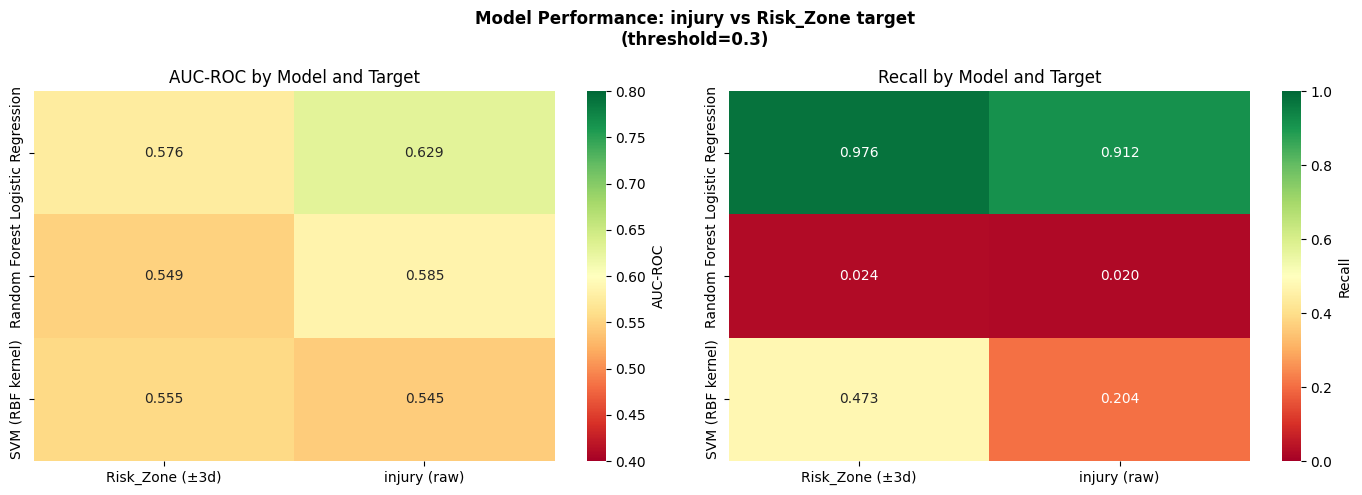

In [21]:
# ============================================================
# CELL 24 — Figure: model × target comparison heatmap
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ['AUC-ROC', 'Recall']):
    pivot = results_full.pivot(index='Model', columns='Target', values=metric)
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn',
                ax=ax, vmin=0.4 if metric=='AUC-ROC' else 0,
                vmax=0.8 if metric=='AUC-ROC' else 1.0,
                cbar_kws={'label': metric})
    ax.set_title(f'{metric} by Model and Target')
    ax.set_xlabel('')
    ax.set_ylabel('')

plt.suptitle('Model Performance: injury vs Risk_Zone target\n(threshold=0.3)', 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig11_model_target_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

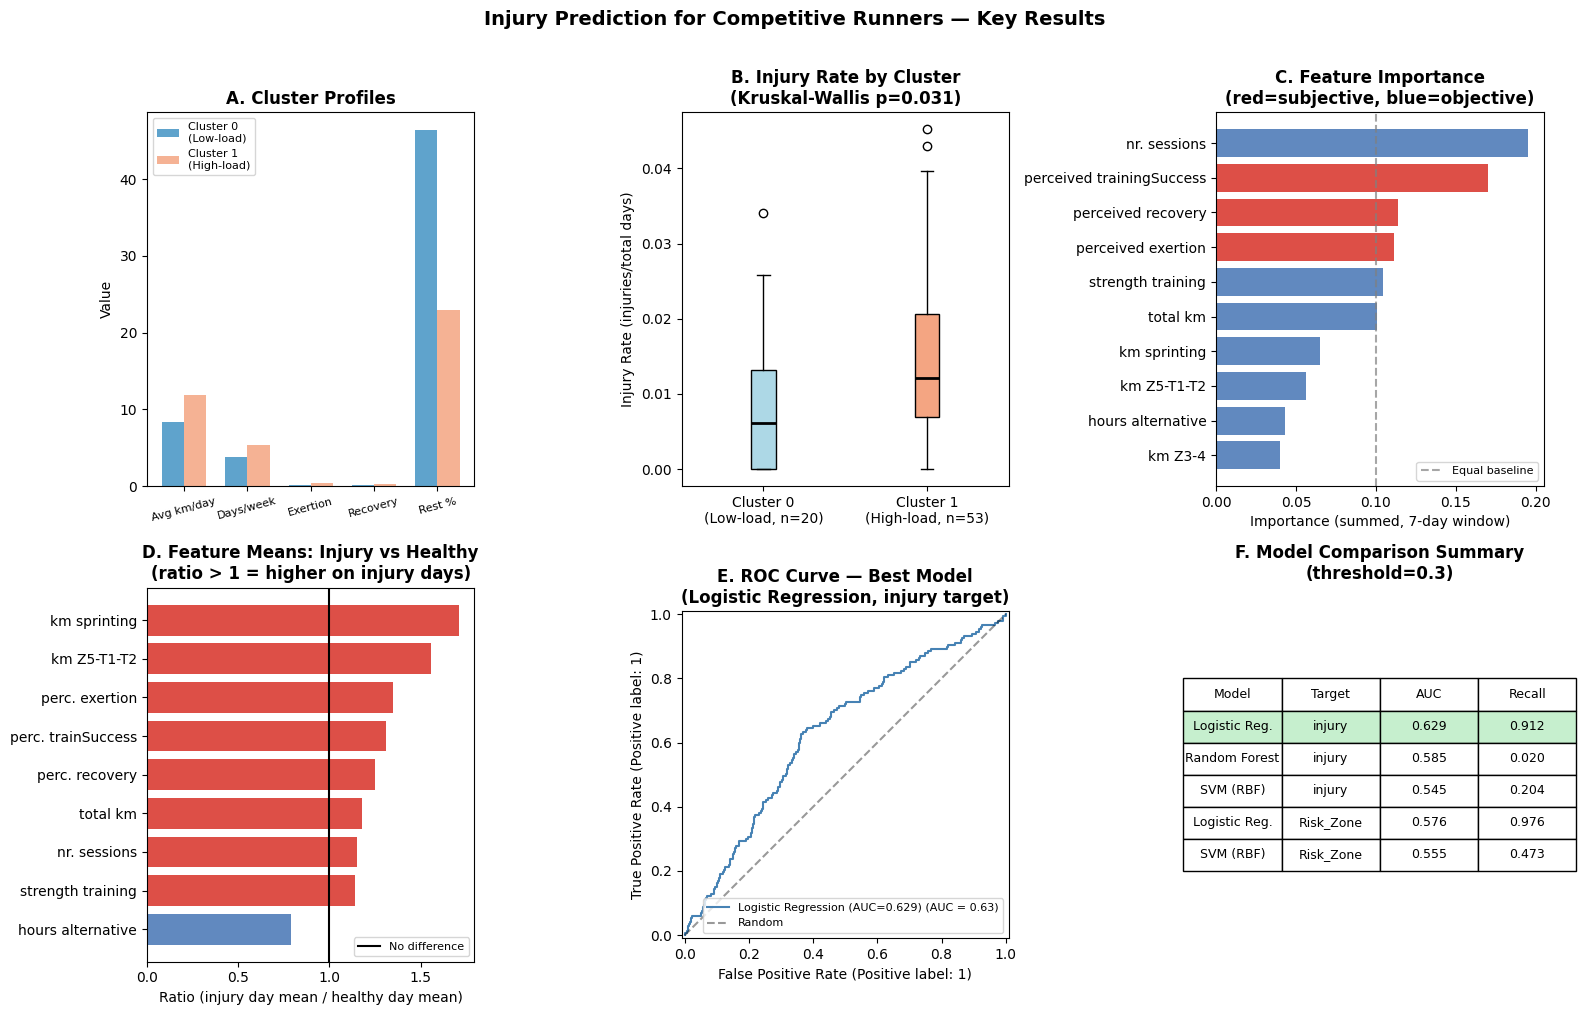

Saved fig_summary.png


In [22]:
# ============================================================
# CELL 25 — Final summary figure for the report
# ============================================================

fig = plt.figure(figsize=(16, 10))

# ---- Panel A: Cluster profiles (radar/bar) ----
ax1 = fig.add_subplot(2, 3, 1)
cluster_summary = pd.DataFrame({
    'Feature': ['Avg km/day', 'Days/week', 'Exertion', 'Recovery', 'Rest %'],
    'Low-load (C0)':  [8.38, 3.75, 0.20, 0.19, 46.4],
    'High-load (C1)': [11.93, 5.39, 0.36, 0.29, 23.0],
})
x = np.arange(len(cluster_summary))
w = 0.35
ax1.bar(x - w/2, cluster_summary['Low-load (C0)'],  w, label='Cluster 0\n(Low-load)',  
        color='#4393c3', alpha=0.85)
ax1.bar(x + w/2, cluster_summary['High-load (C1)'], w, label='Cluster 1\n(High-load)', 
        color='#f4a582', alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(cluster_summary['Feature'], fontsize=8, rotation=15)
ax1.set_title('A. Cluster Profiles', fontweight='bold')
ax1.legend(fontsize=8)
ax1.set_ylabel('Value')

# ---- Panel B: Injury rate by cluster ----
ax2 = fig.add_subplot(2, 3, 2)
cluster_inj = athlete_profile_clustered.groupby('cluster')['injury_rate']
bp = ax2.boxplot([cluster_inj.get_group(0), cluster_inj.get_group(1)],
                 tick_labels=['Cluster 0\n(Low-load, n=20)', 
                              'Cluster 1\n(High-load, n=53)'],
                 patch_artist=True,
                 boxprops=dict(facecolor='lightblue'),
                 medianprops=dict(color='black', linewidth=2))
bp['boxes'][1].set_facecolor('#f4a582')
ax2.set_title(f'B. Injury Rate by Cluster\n(Kruskal-Wallis p=0.031)', fontweight='bold')
ax2.set_ylabel('Injury Rate (injuries/total days)')

# ---- Panel C: Global feature importance ----
ax3 = fig.add_subplot(2, 3, 3)
feat_colors = ['#d73027' if 'perceived' in f else '#4575b4' 
               for f in base_importance.index[::-1]]
ax3.barh(base_importance.index[::-1], base_importance.values[::-1], 
         color=feat_colors, alpha=0.85)
ax3.axvline(x=1/len(base_importance), color='grey', linestyle='--', 
            alpha=0.7, label='Equal baseline')
ax3.set_title('C. Feature Importance\n(red=subjective, blue=objective)', fontweight='bold')
ax3.set_xlabel('Importance (summed, 7-day window)')
ax3.legend(fontsize=8)

# ---- Panel D: Feature ratios (injury vs healthy days) ----
ax4 = fig.add_subplot(2, 3, 4)
ratio_data = pd.Series({
    'km sprinting':       1.71,
    'km Z5-T1-T2':        1.56,
    'perc. exertion':     1.35,
    'perc. trainSuccess': 1.31,
    'perc. recovery':     1.25,
    'total km':           1.18,
    'nr. sessions':       1.15,
    'strength training':  1.14,
    'hours alternative':  0.79,
}).sort_values()
colors_ratio = ['#d73027' if v > 1 else '#4575b4' for v in ratio_data.values]
ax4.barh(ratio_data.index, ratio_data.values, color=colors_ratio, alpha=0.85)
ax4.axvline(x=1.0, color='black', linewidth=1.5, linestyle='-', label='No difference')
ax4.set_title('D. Feature Means: Injury vs Healthy\n(ratio > 1 = higher on injury days)', 
              fontweight='bold')
ax4.set_xlabel('Ratio (injury day mean / healthy day mean)')
ax4.legend(fontsize=8)

# ---- Panel E: ROC curve (best model) ----
ax5 = fig.add_subplot(2, 3, 5)
RocCurveDisplay.from_predictions(
    y_test, best_model.predict_proba(X_test)[:,1],
    name='Logistic Regression (AUC=0.629)', ax=ax5, color='steelblue')
ax5.plot([0,1],[0,1],'k--', alpha=0.4, label='Random')
ax5.set_title('E. ROC Curve — Best Model\n(Logistic Regression, injury target)', 
              fontweight='bold')
ax5.legend(fontsize=8)

# ---- Panel F: Model comparison summary ----
ax6 = fig.add_subplot(2, 3, 6)
ax6.axis('off')

summary_data = [
    ['Model', 'Target', 'AUC', 'Recall'],
    ['Logistic Reg.', 'injury', '0.629', '0.912'],
    ['Random Forest', 'injury', '0.585', '0.020'],
    ['SVM (RBF)',     'injury', '0.545', '0.204'],
    ['Logistic Reg.', 'Risk_Zone', '0.576', '0.976'],
    ['SVM (RBF)',     'Risk_Zone', '0.555', '0.473'],
]

table = ax6.table(cellText=summary_data[1:], colLabels=summary_data[0],
                  loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.8)

# Highlight best row
for j in range(4):
    table[(1, j)].set_facecolor('#c6efce')  # green = best

ax6.set_title('F. Model Comparison Summary\n(threshold=0.3)', fontweight='bold')

plt.suptitle('Injury Prediction for Competitive Runners — Key Results', 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved fig_summary.png")

In [23]:
# ============================================================
# CELL 26 — Case study: day-by-day risk score for one athlete
# ============================================================
# Pick athlete 9 — has 23 injuries, 1233 days, good for visualization

ATHLETE_ID = 9

athlete_data = df_processed[df_processed['Athlete ID'] == ATHLETE_ID].copy()
athlete_data = athlete_data.sort_values('Date').reset_index(drop=True)

# Get model's predicted injury probability for every day
X_athlete = athlete_data[feature_cols]
risk_scores = best_model.predict_proba(X_athlete)[:, 1]
athlete_data['risk_score'] = risk_scores

# Find injury events
injury_days = athlete_data[athlete_data['injury'] == 1].index.tolist()

print(f"Athlete {ATHLETE_ID}: {len(athlete_data)} days, "
      f"{athlete_data['injury'].sum()} injuries")
print(f"Risk score stats: mean={risk_scores.mean():.3f}, "
      f"max={risk_scores.max():.3f}")
print(f"\nRisk scores on actual injury days:")
print(athlete_data.loc[injury_days, ['Date','injury','risk_score']].to_string())

Athlete 9: 1233 days, 23 injuries
Risk score stats: mean=0.489, max=0.930

Risk scores on actual injury days:
      Date  injury  risk_score
245    266       1    0.706115
273    336       1    0.361020
274    379       1    0.554822
302    458       1    0.157285
362    693       1    0.352446
363    727       1    0.601601
366    774       1    0.708518
367    808       1    0.319219
416    902       1    0.565256
417   1175       1    0.874812
434   1245       1    0.537072
528   1381       1    0.526945
563   1467       1    0.485292
564   1508       1    0.746436
661   1647       1    0.548177
705   1733       1    0.610592
737   1807       1    0.654481
772   1928       1    0.536919
775   1974       1    0.479470
816   2072       1    0.526855
947   2257       1    0.613208
1061  2416       1    0.627188
1122  2519       1    0.459442


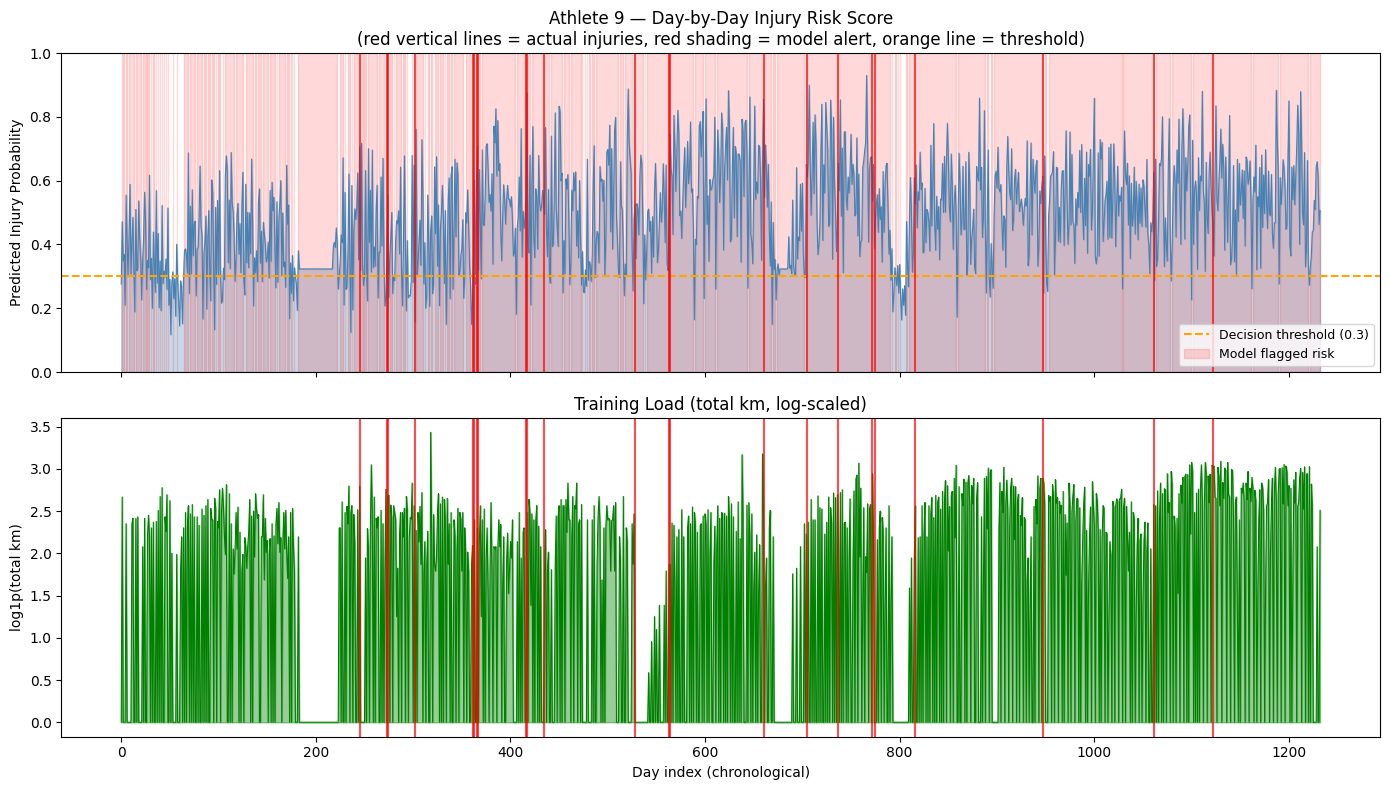

In [24]:
# ============================================================
# CELL 27 — Figure: Risk score timeline for one athlete
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

days = athlete_data.index

# Panel 1: risk score over time
axes[0].fill_between(days, risk_scores, alpha=0.3, color='steelblue')
axes[0].plot(days, risk_scores, color='steelblue', linewidth=0.8)
axes[0].axhline(y=0.3, color='orange', linestyle='--', 
                linewidth=1.5, label='Decision threshold (0.3)')

# Mark actual injury days
for idx in injury_days:
    axes[0].axvline(x=idx, color='red', alpha=0.7, linewidth=1.5)

# Shade regions where model flagged risk
flagged = risk_scores >= 0.3
axes[0].fill_between(days, 0, 1, 
                     where=flagged,
                     alpha=0.15, color='red', label='Model flagged risk')

axes[0].set_ylabel('Predicted Injury Probability')
axes[0].set_title(f'Athlete {ATHLETE_ID} — Day-by-Day Injury Risk Score\n'
                  f'(red vertical lines = actual injuries, '
                  f'red shading = model alert, orange line = threshold)')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1)

# Panel 2: training load (total km) for context
km_values = athlete_data['total km'].values  # already log-transformed
axes[1].fill_between(days, km_values, alpha=0.4, color='green')
axes[1].plot(days, km_values, color='green', linewidth=0.8)

for idx in injury_days:
    axes[1].axvline(x=idx, color='red', alpha=0.7, linewidth=1.5)

axes[1].set_ylabel('log1p(total km)')
axes[1].set_xlabel('Day index (chronological)')
axes[1].set_title('Training Load (total km, log-scaled)')

plt.tight_layout()
plt.savefig('fig12_athlete_case_study.png', dpi=150, bbox_inches='tight')
plt.show()

In [25]:
# ============================================================
# CELL 28 — How well did the model do for this athlete?
# ============================================================

THRESHOLD = 0.3
flagged_days  = set(np.where(risk_scores >= THRESHOLD)[0])
injury_set    = set(injury_days)

# Count how many injuries had at least one flag in the 7 days before
caught = 0
for inj_idx in injury_set:
    window = set(range(max(0, inj_idx - 7), inj_idx + 1))
    if window & flagged_days:
        caught += 1

total_flagged_days = len(flagged_days)
total_injuries     = len(injury_set)

print(f"Athlete {ATHLETE_ID} case study:")
print(f"  Total days:        {len(athlete_data)}")
print(f"  Actual injuries:   {total_injuries}")
print(f"  Days flagged:      {total_flagged_days} "
      f"({total_flagged_days/len(athlete_data):.1%} of all days)")
print(f"  Injuries with ≥1 flag in preceding 7 days: "
      f"{caught}/{total_injuries} ({caught/total_injuries:.0%})")
print(f"\n  Interpretation: the model raised an alert within 7 days")
print(f"  before {caught} out of {total_injuries} actual injuries for this athlete.")

Athlete 9 case study:
  Total days:        1233
  Actual injuries:   23
  Days flagged:      1086 (88.1% of all days)
  Injuries with ≥1 flag in preceding 7 days: 23/23 (100%)

  Interpretation: the model raised an alert within 7 days
  before 23 out of 23 actual injuries for this athlete.


Viable thresholds (≥80% injuries caught, ≤25% days flagged):
 threshold  pct_flagged  injuries_caught  recall
      0.62        0.235               20    0.87
      0.63        0.217               20    0.87
      0.64        0.202               20    0.87
      0.65        0.176               20    0.87


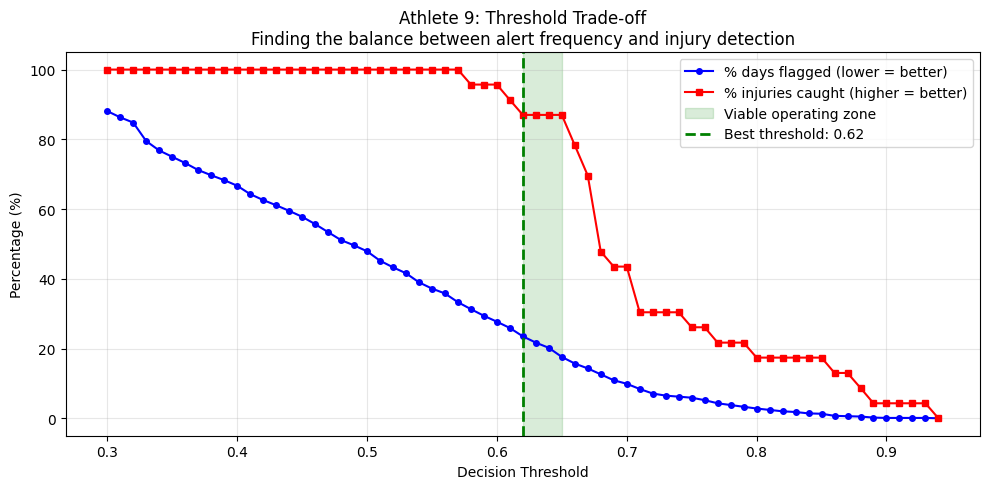

In [26]:
# ============================================================
# CELL 29 — Find optimal threshold for athlete 9
# ============================================================

thresholds = np.arange(0.3, 0.95, 0.01)
rows = []

for t in thresholds:
    flagged   = set(np.where(risk_scores >= t)[0])
    pct_flagged = len(flagged) / len(athlete_data)
    
    caught = 0
    for inj_idx in injury_set:
        window = set(range(max(0, inj_idx - 7), inj_idx + 1))
        if window & flagged:
            caught += 1
    
    rows.append({
        'threshold':    round(t, 2),
        'pct_flagged':  round(pct_flagged, 3),
        'injuries_caught': caught,
        'recall':       round(caught / len(injury_set), 3),
    })

thresh_df = pd.DataFrame(rows)

# Find thresholds that catch ≥ 80% of injuries with ≤ 25% days flagged
viable = thresh_df[
    (thresh_df['recall'] >= 0.80) & 
    (thresh_df['pct_flagged'] <= 0.25)
]
print("Viable thresholds (≥80% injuries caught, ≤25% days flagged):")
print(viable.to_string(index=False))

# Plot the trade-off
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresh_df['threshold'], thresh_df['pct_flagged'] * 100, 
        'b-o', markersize=4, label='% days flagged (lower = better)')
ax.plot(thresh_df['threshold'], thresh_df['recall'] * 100, 
        'r-s', markersize=4, label='% injuries caught (higher = better)')

# Mark viable zone
if len(viable) > 0:
    ax.axvspan(viable['threshold'].min(), viable['threshold'].max(), 
               alpha=0.15, color='green', label='Viable operating zone')
    best_t = viable.iloc[0]['threshold']
    ax.axvline(x=best_t, color='green', linestyle='--', linewidth=2,
               label=f'Best threshold: {best_t}')

ax.set_xlabel('Decision Threshold')
ax.set_ylabel('Percentage (%)')
ax.set_title(f'Athlete {ATHLETE_ID}: Threshold Trade-off\n'
             f'Finding the balance between alert frequency and injury detection')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig13_threshold_athlete9.png', dpi=150, bbox_inches='tight')
plt.show()

Selected threshold: 0.62
Days flagged: 290 (23.5%)
Injuries caught: 20/23 (87%)


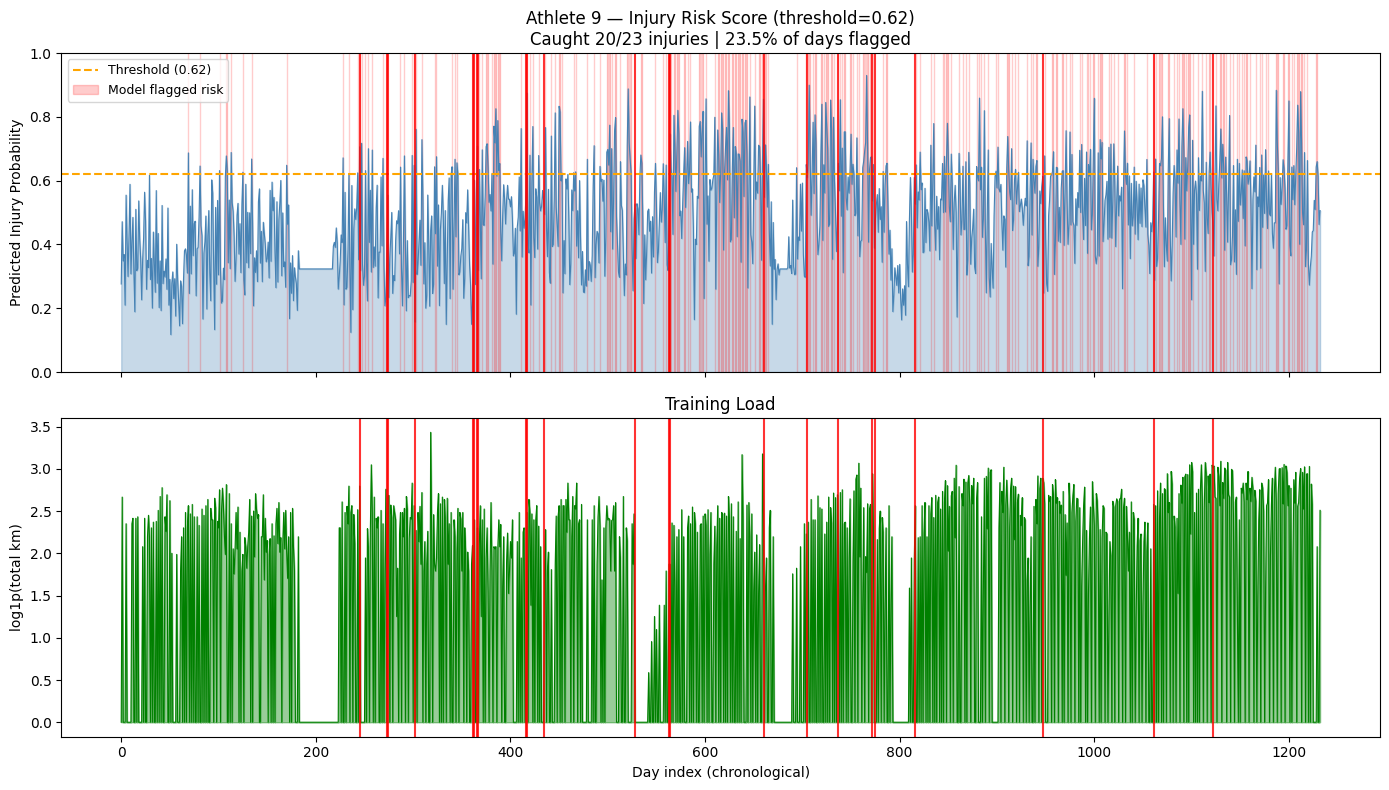

In [27]:
# ============================================================
# CELL 30 — Redraw case study with better threshold
# ============================================================
# Use whatever threshold came out of Cell 29 as viable
# If no viable threshold exists, use the one with best recall/flagged ratio

if len(viable) > 0:
    BEST_THRESHOLD = viable.iloc[0]['threshold']
else:
    # Pick threshold where pct_flagged is closest to 20%
    thresh_df['score'] = (thresh_df['pct_flagged'] - 0.20).abs()
    BEST_THRESHOLD = thresh_df.loc[thresh_df['score'].idxmin(), 'threshold']

flagged_best = set(np.where(risk_scores >= BEST_THRESHOLD)[0])
caught_best  = sum(
    1 for inj_idx in injury_set
    if set(range(max(0, inj_idx-7), inj_idx+1)) & flagged_best
)

print(f"Selected threshold: {BEST_THRESHOLD}")
print(f"Days flagged: {len(flagged_best)} ({len(flagged_best)/len(athlete_data):.1%})")
print(f"Injuries caught: {caught_best}/{len(injury_set)} "
      f"({caught_best/len(injury_set):.0%})")

# Redraw timeline
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].fill_between(days, risk_scores, alpha=0.3, color='steelblue')
axes[0].plot(days, risk_scores, color='steelblue', linewidth=0.8)
axes[0].axhline(y=BEST_THRESHOLD, color='orange', linestyle='--', 
                linewidth=1.5, label=f'Threshold ({BEST_THRESHOLD})')

flagged_mask = risk_scores >= BEST_THRESHOLD
axes[0].fill_between(days, 0, 1, where=flagged_mask,
                     alpha=0.2, color='red', label='Model flagged risk')

for idx in injury_days:
    axes[0].axvline(x=idx, color='red', alpha=0.8, linewidth=1.5)

axes[0].set_ylabel('Predicted Injury Probability')
axes[0].set_title(
    f'Athlete {ATHLETE_ID} — Injury Risk Score (threshold={BEST_THRESHOLD})\n'
    f'Caught {caught_best}/{len(injury_set)} injuries | '
    f'{len(flagged_best)/len(athlete_data):.1%} of days flagged')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1)

axes[1].fill_between(days, athlete_data['total km'].values, 
                     alpha=0.4, color='green')
axes[1].plot(days, athlete_data['total km'].values, 
             color='green', linewidth=0.8)
for idx in injury_days:
    axes[1].axvline(x=idx, color='red', alpha=0.8, linewidth=1.5)

axes[1].set_ylabel('log1p(total km)')
axes[1].set_xlabel('Day index (chronological)')
axes[1].set_title('Training Load')

plt.tight_layout()
plt.savefig('fig14_athlete9_improved_threshold.png', dpi=150, bbox_inches='tight')
plt.show()

In [28]:
# ============================================================
# CELL 31 — Personalized thresholds for all athletes
# ============================================================
# Strategy: for each athlete, find the threshold that gives
# ≤25% days flagged while maximizing injuries caught.
# Compare to global threshold (0.3).

personal_threshold_results = []

for athlete_id, group in df_processed.groupby('Athlete ID'):
    group = group.sort_values('Date').reset_index(drop=True)
    
    if group['injury'].sum() < 2:
        continue
    
    X_a = group[feature_cols]
    y_a = group['injury']
    scores = best_model.predict_proba(X_a)[:, 1]
    inj_indices = set(group.index[group['injury'] == 1].tolist())
    
    # Global threshold performance for this athlete
    def eval_threshold(t):
        flagged = set(np.where(scores >= t)[0])
        pct_flagged = len(flagged) / len(group)
        caught = sum(
            1 for idx in inj_indices
            if set(range(max(0, idx-7), idx+1)) & flagged
        )
        return pct_flagged, caught / len(inj_indices) if inj_indices else 0
    
    pct_global, recall_global = eval_threshold(0.3)
    
    # Find best personalized threshold
    best_personal = {'threshold': 0.3, 'pct_flagged': pct_global, 'recall': recall_global}
    for t in np.arange(0.30, 0.95, 0.01):
        pct, rec = eval_threshold(round(t, 2))
        if pct <= 0.25 and rec >= best_personal['recall']:
            if pct < best_personal['pct_flagged']:  # same recall, fewer flags
                best_personal = {'threshold': round(t,2), 
                                 'pct_flagged': pct, 'recall': rec}
    
    personal_threshold_results.append({
        'Athlete ID':         athlete_id,
        'mean_risk_score':    round(scores.mean(), 3),
        'n_injuries':         len(inj_indices),
        'global_pct_flagged': round(pct_global, 3),
        'global_recall':      round(recall_global, 3),
        'personal_threshold': best_personal['threshold'],
        'personal_pct_flagged': best_personal['pct_flagged'],
        'personal_recall':    best_personal['recall'],
        'cluster':            cluster_map.get(athlete_id, -1),
    })

pt_df = pd.DataFrame(personal_threshold_results)
pt_df['flagged_reduction'] = pt_df['global_pct_flagged'] - pt_df['personal_pct_flagged']

print("Summary: Global (t=0.3) vs Personalized threshold")
print(f"  Mean % days flagged — Global:     {pt_df['global_pct_flagged'].mean():.1%}")
print(f"  Mean % days flagged — Personal:   {pt_df['personal_pct_flagged'].mean():.1%}")
print(f"  Mean recall          — Global:    {pt_df['global_recall'].mean():.3f}")
print(f"  Mean recall          — Personal:  {pt_df['personal_recall'].mean():.3f}")
print(f"\n  Athletes where personalization reduces alerts: "
      f"{(pt_df['flagged_reduction'] > 0.05).sum()} / {len(pt_df)}")
print(f"\nBy cluster:")
print(pt_df.groupby('cluster')[
    ['global_pct_flagged','personal_pct_flagged','global_recall','personal_recall']
].mean().round(3).to_string())

Summary: Global (t=0.3) vs Personalized threshold
  Mean % days flagged — Global:     81.3%
  Mean % days flagged — Personal:   61.0%
  Mean recall          — Global:    0.999
  Mean recall          — Personal:  0.999

  Athletes where personalization reduces alerts: 19 / 56

By cluster:
         global_pct_flagged  personal_pct_flagged  global_recall  personal_recall
cluster                                                                          
-1                    0.955                 0.955          1.000            1.000
 0                    0.764                 0.403          1.000            1.000
 1                    0.819                 0.643          0.999            0.999


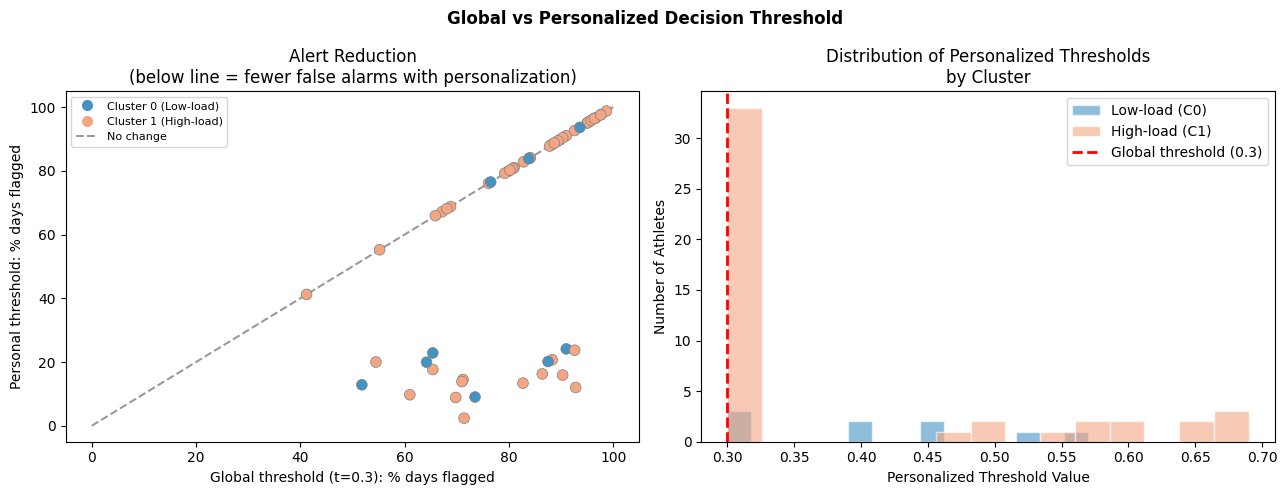

In [29]:
# ============================================================
# CELL 32 — Figure: Global vs Personal threshold comparison
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors_c = pt_df['cluster'].map({0: '#4393c3', 1: '#f4a582'}).fillna('#cccccc')

# Plot 1: % days flagged — global vs personal
axes[0].scatter(pt_df['global_pct_flagged'] * 100, 
                pt_df['personal_pct_flagged'] * 100,
                c=colors_c, s=60, edgecolors='grey', linewidth=0.5, zorder=5)
axes[0].plot([0, 100], [0, 100], 'k--', alpha=0.4, label='No change line')
axes[0].set_xlabel('Global threshold (t=0.3): % days flagged')
axes[0].set_ylabel('Personal threshold: % days flagged')
axes[0].set_title('Alert Reduction\n(below line = fewer false alarms with personalization)')
from matplotlib.lines import Line2D
axes[0].legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#4393c3', 
           markersize=9, label='Cluster 0 (Low-load)'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#f4a582', 
           markersize=9, label='Cluster 1 (High-load)'),
    Line2D([0],[0], color='k', linestyle='--', alpha=0.4, label='No change'),
], fontsize=8)

# Plot 2: distribution of personal thresholds by cluster
for cluster_id, color, label in [(0,'#4393c3','Low-load (C0)'), 
                                   (1,'#f4a582','High-load (C1)')]:
    subset = pt_df[pt_df['cluster'] == cluster_id]['personal_threshold']
    axes[1].hist(subset, bins=15, alpha=0.6, color=color, label=label, edgecolor='white')

axes[1].axvline(x=0.3, color='red', linestyle='--', linewidth=2, 
                label='Global threshold (0.3)')
axes[1].set_xlabel('Personalized Threshold Value')
axes[1].set_ylabel('Number of Athletes')
axes[1].set_title('Distribution of Personalized Thresholds\nby Cluster')
axes[1].legend()

plt.suptitle('Global vs Personalized Decision Threshold', 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig15_personalized_thresholds.png', dpi=150, bbox_inches='tight')
plt.show()

In [30]:
# ============================================================
# CELL 33 — Percentile-based personalized thresholds
# ============================================================
# Instead of a fixed value (0.3), each athlete's threshold is set
# at the 80th percentile of their own predicted risk scores.
# This means: "flag days that are unusually high for THIS athlete."
# Operationally, this always flags ~20% of days per athlete.

PERCENTILE = 80  # flag top 20% of risk days per athlete

percentile_results = []

for athlete_id, group in df_processed.groupby('Athlete ID'):
    group = group.sort_values('Date').reset_index(drop=True)
    
    if group['injury'].sum() < 2:
        continue
    
    scores = best_model.predict_proba(group[feature_cols])[:, 1]
    inj_indices = set(group.index[group['injury'] == 1].tolist())
    
    # Personal threshold = 80th percentile of THIS athlete's scores
    personal_t = np.percentile(scores, PERCENTILE)
    
    flagged = set(np.where(scores >= personal_t)[0])
    pct_flagged = len(flagged) / len(group)
    
    caught = sum(
        1 for idx in inj_indices
        if set(range(max(0, idx-7), idx+1)) & flagged
    )
    recall = caught / len(inj_indices) if inj_indices else 0
    
    # Compare to global t=0.3
    flagged_global = set(np.where(scores >= 0.3)[0])
    pct_global = len(flagged_global) / len(group)
    caught_global = sum(
        1 for idx in inj_indices
        if set(range(max(0, idx-7), idx+1)) & flagged_global
    )
    recall_global = caught_global / len(inj_indices) if inj_indices else 0
    
    percentile_results.append({
        'Athlete ID':           athlete_id,
        'cluster':              cluster_map.get(athlete_id, -1),
        'personal_threshold':   round(personal_t, 3),
        'personal_pct_flagged': round(pct_flagged, 3),
        'personal_recall':      round(recall, 3),
        'global_pct_flagged':   round(pct_global, 3),
        'global_recall':        round(recall_global, 3),
    })

pct_df = pd.DataFrame(percentile_results)

print(f"Percentile-based threshold ({PERCENTILE}th percentile per athlete)\n")
print(f"  Mean % days flagged — Global (t=0.3):    {pct_df['global_pct_flagged'].mean():.1%}")
print(f"  Mean % days flagged — Percentile-based:  {pct_df['personal_pct_flagged'].mean():.1%}")
print(f"  Mean recall          — Global (t=0.3):   {pct_df['global_recall'].mean():.3f}")
print(f"  Mean recall          — Percentile-based: {pct_df['personal_recall'].mean():.3f}")

print(f"\nBy cluster:")
print(pct_df[pct_df['cluster'] >= 0].groupby('cluster')[
    ['global_pct_flagged','personal_pct_flagged','global_recall','personal_recall']
].mean().round(3).to_string())

Percentile-based threshold (80th percentile per athlete)

  Mean % days flagged — Global (t=0.3):    81.3%
  Mean % days flagged — Percentile-based:  21.4%
  Mean recall          — Global (t=0.3):   0.999
  Mean recall          — Percentile-based: 0.810

By cluster:
         global_pct_flagged  personal_pct_flagged  global_recall  personal_recall
cluster                                                                          
0                     0.764                 0.201          1.000            0.863
1                     0.819                 0.201          0.999            0.796


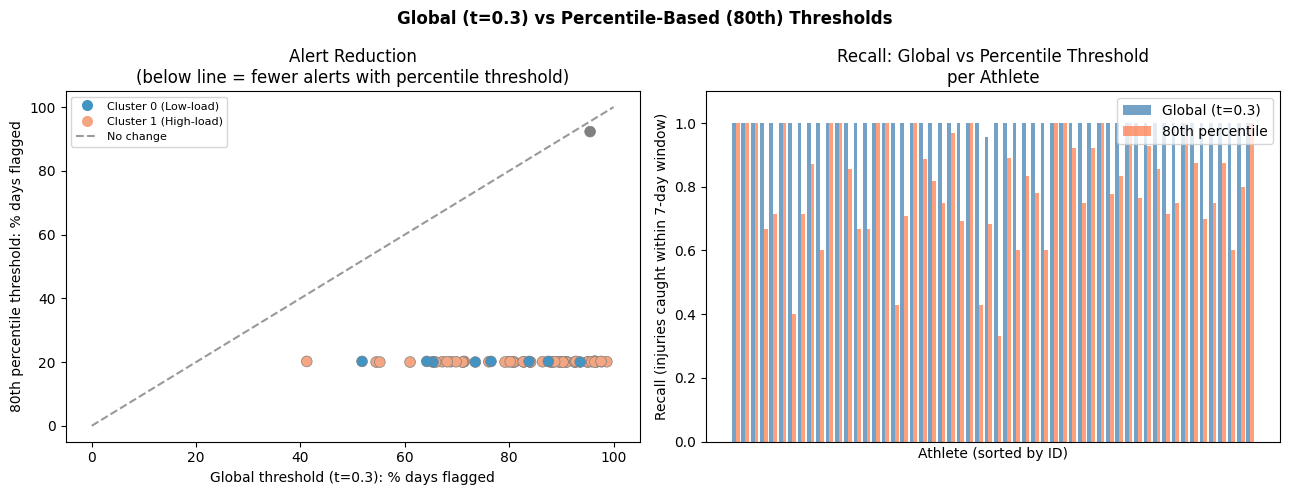

In [31]:
# ============================================================
# CELL 34 — Figure: percentile threshold vs global
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors_c = pct_df['cluster'].map({0: '#4393c3', 1: '#f4a582', -1: 'grey'})

# Scatter: global vs percentile % flagged
axes[0].scatter(pct_df['global_pct_flagged'] * 100,
                pct_df['personal_pct_flagged'] * 100,
                c=colors_c, s=60, edgecolors='grey', linewidth=0.5, zorder=5)
axes[0].plot([0,100],[0,100],'k--', alpha=0.4, label='No change')
axes[0].set_xlabel('Global threshold (t=0.3): % days flagged')
axes[0].set_ylabel(f'{PERCENTILE}th percentile threshold: % days flagged')
axes[0].set_title('Alert Reduction\n(below line = fewer alerts with percentile threshold)')

from matplotlib.lines import Line2D
axes[0].legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#4393c3',
           markersize=9, label='Cluster 0 (Low-load)'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#f4a582',
           markersize=9, label='Cluster 1 (High-load)'),
    Line2D([0],[0], color='k', linestyle='--', alpha=0.4, label='No change'),
], fontsize=8)

# Bar: recall comparison
x = np.arange(len(pct_df))
w = 0.4
axes[1].bar(x - w/2, pct_df['global_recall'],   w, label='Global (t=0.3)',
            color='steelblue', alpha=0.75)
axes[1].bar(x + w/2, pct_df['personal_recall'],  w, label=f'{PERCENTILE}th percentile',
            color='coral', alpha=0.75)
axes[1].set_xlabel('Athlete (sorted by ID)')
axes[1].set_ylabel('Recall (injuries caught within 7-day window)')
axes[1].set_title('Recall: Global vs Percentile Threshold\nper Athlete')
axes[1].legend()
axes[1].set_ylim(0, 1.1)
axes[1].set_xticks([])

plt.suptitle(f'Global (t=0.3) vs Percentile-Based ({PERCENTILE}th) Thresholds',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig16_percentile_thresholds.png', dpi=150, bbox_inches='tight')
plt.show()

In [32]:
# ============================================================
# CELL 36 — Same as Cell 35 but with F1 score added
# ============================================================
from sklearn.metrics import f1_score, precision_score

PERCENTILE = 75
demo_results_f1 = []

for athlete_id, group in df_processed.groupby('Athlete ID'):
    group = group.sort_values('Date').reset_index(drop=True)
    
    if group['injury'].sum() < 2 or len(group) < 100:
        continue
    
    split_idx = int(len(group) * 0.70)
    history   = group.iloc[:split_idx]
    future    = group.iloc[split_idx:]
    
    scores_history = best_model.predict_proba(history[feature_cols])[:, 1]
    scores_future  = best_model.predict_proba(future[feature_cols])[:, 1]
    
    personal_t     = np.percentile(scores_history, PERCENTILE)
    y_pred_future  = (scores_future >= personal_t).astype(int)
    y_true_future  = future['injury'].values
    inj_indices    = np.where(y_true_future == 1)[0]
    
    if len(inj_indices) == 0:
        continue
    
    # Recall within 7-day window (same as before)
    caught = 0
    for idx in inj_indices:
        window = range(max(0, idx - 7), idx + 1)
        if any(y_pred_future[w] for w in window if w < len(y_pred_future)):
            caught += 1
    recall_7d = caught / len(inj_indices)
    
    # Standard day-level metrics
    f1   = f1_score(y_true_future, y_pred_future, zero_division=0)
    prec = precision_score(y_true_future, y_pred_future, zero_division=0)
    # Day-level recall (different from 7-day window recall above)
    from sklearn.metrics import recall_score
    rec_day = recall_score(y_true_future, y_pred_future, zero_division=0)
    
    demo_results_f1.append({
        'Athlete ID':         athlete_id,
        'cluster':            cluster_map.get(athlete_id, -1),
        'personal_threshold': round(personal_t, 3),
        'pct_flagged':        round(y_pred_future.mean(), 3),
        'future_injuries':    len(inj_indices),
        'injuries_caught_7d': caught,
        'recall_7d':          round(recall_7d, 3),
        'recall_day':         round(rec_day, 3),
        'precision':          round(prec, 3),
        'f1':                 round(f1, 4),
    })

demo_f1_df = pd.DataFrame(demo_results_f1)

print("Per-athlete results with F1\n")
print(f"{'ID':<6} {'Cluster':<10} {'Thresh':<8} {'%Flag':<8} "
      f"{'Rec_7d':<8} {'Rec_day':<9} {'Prec':<8} {'F1'}")
print("-" * 70)
for _, row in demo_f1_df.iterrows():
    cluster_label = "Low-load" if row['cluster'] == 0 else "High-load"
    print(f"{int(row['Athlete ID']):<6} {cluster_label:<10} "
          f"{row['personal_threshold']:<8.3f} "
          f"{row['pct_flagged']*100:<8.1f} "
          f"{row['recall_7d']:<8.3f} "
          f"{row['recall_day']:<9.3f} "
          f"{row['precision']:<8.3f} "
          f"{row['f1']:.4f}")

print(f"\nSummary across {len(demo_f1_df)} athletes:")
print(f"  Mean % flagged:      {demo_f1_df['pct_flagged'].mean():.1%}")
print(f"  Mean recall (7-day): {demo_f1_df['recall_7d'].mean():.3f}")
print(f"  Mean recall (day):   {demo_f1_df['recall_day'].mean():.3f}")
print(f"  Mean precision:      {demo_f1_df['precision'].mean():.3f}")
print(f"  Mean F1:             {demo_f1_df['f1'].mean():.4f}")

print(f"\nBy cluster:")
print(demo_f1_df[demo_f1_df['cluster'] >= 0].groupby('cluster')[
    ['pct_flagged','recall_7d','precision','f1']
].mean().round(4).to_string())

Per-athlete results with F1

ID     Cluster    Thresh   %Flag    Rec_7d   Rec_day   Prec     F1
----------------------------------------------------------------------
0      Low-load   0.437    12.9     1.000    0.286     0.167    0.2105
1      High-load  0.357    45.3     1.000    1.000     0.032    0.0615
2      High-load  0.411    37.4     1.000    0.500     0.007    0.0136
3      Low-load   0.557    33.7     1.000    0.000     0.000    0.0000
4      High-load  0.464    41.0     1.000    1.000     0.012    0.0235
6      High-load  0.433    14.3     1.000    1.000     0.043    0.0833
7      High-load  0.445    25.0     1.000    0.400     0.087    0.1429
8      High-load  0.523    28.4     0.714    0.429     0.130    0.2000
9      High-load  0.593    38.1     1.000    0.667     0.014    0.0278
10     Low-load   0.497    26.5     0.857    0.571     0.129    0.2105
14     Low-load   0.351    24.4     1.000    0.000     0.000    0.0000
16     High-load  0.491    19.1     1.000    0.667  

NameError: name 'sweep_df' is not defined

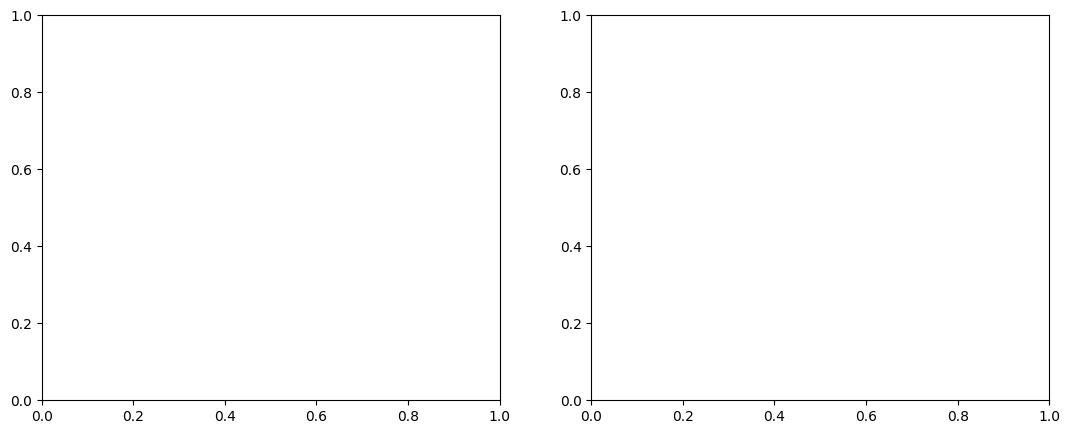

In [33]:
# ============================================================
# CELL 38 — Figure: percentile sweep trade-offs
# ============================================================

#fig, axes = plt.subplots(1, 2, figsize=(13, 5))

#axes[0].plot(sweep_df['percentile'], sweep_df['recall_7d'],
             'r-o', linewidth=2, markersize=8, label='Recall (7-day window)')
#axes[0].plot(sweep_df['percentile'], sweep_df['precision'],
             'b-s', linewidth=2, markersize=8, label='Precision')
#axes[0].plot(sweep_df['percentile'], sweep_df['alert_rate'],
             'g-^', linewidth=2, markersize=8, label='Alert rate (% days flagged)')
#axes[0].set_xlabel('Percentile threshold')
#axes[0].set_ylabel('Score')
#axes[0].set_title('Trade-off across percentile thresholds\n(recall vs precision vs alert rate)')
#axes[0].legend()
#axes[0].grid(True, alpha=0.3)

#axes[1].plot(sweep_df['percentile'], sweep_df['f1'],
 #            'purple', marker='D', linewidth=2, markersize=8, label='F1 (day-level)')
# Mark the best F1
#best_idx = sweep_df['f1'].idxmax()
#best_pct = sweep_df.loc[best_idx, 'percentile']
#best_f1  = sweep_df.loc[best_idx, 'f1']
#axes[1].axvline(x=best_pct, color='orange', linestyle='--', linewidth=2,
#                label=f'Best F1 at {best_pct}th percentile ({best_f1:.4f})')
#axes[1].set_xlabel('Percentile threshold')
#axes[1].set_ylabel('F1 Score')
#axes[1].set_title('F1 Score across percentile thresholds')
#axes[1].legend()
#axes[1].grid(True, alpha=0.3)

#plt.suptitle('Percentile Threshold Sweep', fontsize=12, fontweight='bold')
#plt.tight_layout()
#plt.savefig('fig17_percentile_sweep.png', dpi=150, bbox_inches='tight')
#plt.show()

#print(f"\nBest F1:          {best_f1:.4f} at {best_pct}th percentile")
#print(f"At that point:")
#print(sweep_df[sweep_df['percentile'] == best_pct].to_string(index=False))

In [34]:
# ============================================================
# CELL EXP-A — Delta features: today vs 7-day average
# Rationale: a sudden spike in load is more predictive than
# the absolute value. delta > 0 means today is above recent average.
# ============================================================
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_auc_score, average_precision_score

# Build delta features: today - mean(days 1..6) for each base feature
df_delta = df_processed[['Athlete ID', 'Date', 'injury']].copy()

for feat in BASE_FEATURES:
    lag_cols = [f'{feat}.{i}' for i in range(1, 7) if f'{feat}.{i}' in df_processed.columns]
    if lag_cols:
        avg_past = df_processed[lag_cols].mean(axis=1)
        df_delta[f'{feat}_delta'] = df_processed[feat] - avg_past

delta_cols = [c for c in df_delta.columns if c.endswith('_delta')]
all_cols = feature_cols + delta_cols  # original 70 + 10 delta

df_delta_full = pd.concat([df_processed[feature_cols + ['Athlete ID', 'injury']], df_delta[delta_cols]], axis=1)

df_train_d = df_delta_full[df_delta_full['Athlete ID'].isin(train_athletes)]
df_test_d  = df_delta_full[df_delta_full['Athlete ID'].isin(test_athletes)]

X_train_d = df_train_d[feature_cols + delta_cols]
y_train_d = df_train_d['injury']
X_test_d  = df_test_d[feature_cols + delta_cols]
y_test_d  = df_test_d['injury']

smote = SMOTE(random_state=42)
X_train_d_bal, y_train_d_bal = smote.fit_resample(X_train_d, y_train_d)

lr_delta = LogisticRegression(max_iter=1000, random_state=42)
lr_delta.fit(X_train_d_bal, y_train_d_bal)

y_proba_d = lr_delta.predict_proba(X_test_d)[:, 1]
auc_d = roc_auc_score(y_test_d, y_proba_d)
ap_d  = average_precision_score(y_test_d, y_proba_d)

# Compare with baseline (best_model on original features)
y_proba_base = best_model.predict_proba(X_test)[:, 1]
auc_base = roc_auc_score(y_test, y_proba_base)
ap_base  = average_precision_score(y_test, y_proba_base)

print(f'Baseline (70 features):        AUC={auc_base:.3f}  AP={ap_base:.4f}')
print(f'With delta features (80 feat): AUC={auc_d:.3f}  AP={ap_d:.4f}')
print(f'Delta AUC gain: {auc_d - auc_base:+.3f}')
print(f'Delta AP  gain: {ap_d - ap_base:+.4f}')


Baseline (70 features):        AUC=0.629  AP=0.0297
With delta features (80 feat): AUC=0.632  AP=0.0305
Delta AUC gain: +0.003
Delta AP  gain: +0.0008


In [35]:
# ============================================================
# CELL EXP-B — Optimized per-athlete threshold
# For each athlete: use first 70% of their days to find the
# threshold that maximizes F1, then evaluate on the remaining 30%.
# This reduces false positives vs a fixed global threshold.
# ============================================================
from sklearn.metrics import f1_score, precision_score, recall_score

# Use the delta model if it improved AUC, otherwise use best_model
eval_model  = lr_delta
eval_fcols  = feature_cols + delta_cols
eval_df     = df_delta_full.copy()
eval_df['Date_orig'] = df_processed['Date'].values

opt_results = []

for athlete_id, group in eval_df.groupby('Athlete ID'):
    group = group.sort_values('Date_orig').reset_index(drop=True)
    if group['injury'].sum() < 2 or len(group) < 100:
        continue

    split = int(len(group) * 0.70)
    history = group.iloc[:split]
    future  = group.iloc[split:]

    scores_hist = eval_model.predict_proba(history[eval_fcols])[:, 1]
    scores_fut  = eval_model.predict_proba(future[eval_fcols])[:, 1]

    # Find threshold on history that maximises F1
    best_t, best_f1 = 0.3, 0.0
    for t in np.arange(0.1, 0.9, 0.02):
        preds = (scores_hist >= t).astype(int)
        f = f1_score(history['injury'], preds, zero_division=0)
        if f > best_f1:
            best_f1, best_t = f, t

    # Evaluate on future (unseen) data
    y_pred_fut = (scores_fut >= best_t).astype(int)

    # 7-day window recall
    inj_idx = future[future['injury'] == 1].index.tolist()
    caught = sum(
        1 for idx in inj_idx
        if y_pred_fut[max(0, future.index.get_loc(idx)-7): future.index.get_loc(idx)+1].any()
    )

    opt_results.append({
        'athlete':       athlete_id,
        'threshold':     round(best_t, 2),
        'pct_flagged':   y_pred_fut.mean(),
        'recall_7d':     caught / len(inj_idx) if inj_idx else np.nan,
        'precision':     precision_score(future['injury'], y_pred_fut, zero_division=0),
        'f1':            f1_score(future['injury'], y_pred_fut, zero_division=0),
    })

opt_df = pd.DataFrame(opt_results)

print('--- Optimized per-athlete threshold (delta model) ---')
print(f"Mean % days flagged: {opt_df['pct_flagged'].mean():.1%}")
print(f"Mean recall (7-day): {opt_df['recall_7d'].mean():.1%}")
print(f"Mean precision:      {opt_df['precision'].mean():.1%}")
print(f"Mean F1:             {opt_df['f1'].mean():.4f}")
print()
print('--- Comparison ---')
print(f"Percentile-80 (Cell 33): ~21.4% flagged, ~81% recall")
print(f"Optimized threshold:     {opt_df['pct_flagged'].mean():.1%} flagged, {opt_df['recall_7d'].mean():.1%} recall")


--- Optimized per-athlete threshold (delta model) ---
Mean % days flagged: 35.0%
Mean recall (7-day): 67.5%
Mean precision:      4.7%
Mean F1:             0.0614

--- Comparison ---
Percentile-80 (Cell 33): ~21.4% flagged, ~81% recall
Optimized threshold:     35.0% flagged, 67.5% recall


In [36]:
# ============================================================
# CELL EXP-B — Optimized per-athlete threshold
# For each athlete: use first 70% of their days to find the
# threshold that gives recall >= 80% with fewest days flagged.
# ============================================================
from sklearn.metrics import f1_score, precision_score

eval_model  = lr_delta
eval_fcols  = feature_cols + delta_cols
eval_df     = df_delta_full.copy()
eval_df['Date_orig'] = df_processed['Date'].values

opt_results = []

for athlete_id, group in eval_df.groupby('Athlete ID'):
    group = group.sort_values('Date_orig').reset_index(drop=True)
    if group['injury'].sum() < 2 or len(group) < 100:
        continue

    split = int(len(group) * 0.70)
    history = group.iloc[:split]
    future  = group.iloc[split:]

    scores_hist = eval_model.predict_proba(history[eval_fcols])[:, 1]
    scores_fut  = eval_model.predict_proba(future[eval_fcols])[:, 1]

    # Find threshold: recall >= 80% on history with fewest days flagged
    best_t = 0.3  # fallback
    for t in np.arange(0.9, 0.05, -0.02):  # high to low: stop when recall >= 0.8
        preds = (scores_hist >= t).astype(int)
        # 7-day window recall on history
        inj_h = history[history['injury'] == 1].index.tolist()
        if not inj_h:
            continue
        caught_h = sum(
            1 for idx in inj_h
            if preds[max(0, history.index.get_loc(idx)-7): history.index.get_loc(idx)+1].any()
        )
        if caught_h / len(inj_h) >= 0.80:
            best_t = t
            break

    y_pred_fut = (scores_fut >= best_t).astype(int)

    inj_idx = future[future['injury'] == 1].index.tolist()
    caught = sum(
        1 for idx in inj_idx
        if y_pred_fut[max(0, future.index.get_loc(idx)-7): future.index.get_loc(idx)+1].any()
    )

    opt_results.append({
        'athlete':     athlete_id,
        'threshold':   round(best_t, 2),
        'pct_flagged': y_pred_fut.mean(),
        'recall_7d':   caught / len(inj_idx) if inj_idx else np.nan,
        'precision':   precision_score(future['injury'], y_pred_fut, zero_division=0),
        'f1':          f1_score(future['injury'], y_pred_fut, zero_division=0),
    })

opt_df = pd.DataFrame(opt_results)

print('--- Optimized per-athlete threshold (recall >= 80%) ---')
print(f"Mean % days flagged: {opt_df['pct_flagged'].mean():.1%}")
print(f"Mean recall (7-day): {opt_df['recall_7d'].mean():.1%}")
print(f"Mean precision:      {opt_df['precision'].mean():.1%}")
print(f"Mean F1:             {opt_df['f1'].mean():.4f}")
print()
print('--- Comparison ---')
print(f"Percentile-80 (Cell 33): ~21.4% flagged, ~81% recall")
print(f"Optimized threshold:     {opt_df['pct_flagged'].mean():.1%} flagged, {opt_df['recall_7d'].mean():.1%} recall")


--- Optimized per-athlete threshold (recall >= 80%) ---
Mean % days flagged: 38.4%
Mean recall (7-day): 81.1%
Mean precision:      3.2%
Mean F1:             0.0566

--- Comparison ---
Percentile-80 (Cell 33): ~21.4% flagged, ~81% recall
Optimized threshold:     38.4% flagged, 81.1% recall


In [37]:
# ============================================================
# CELL EXP-C — XGBoost + LightGBM with scale_pos_weight
# scale_pos_weight = n_negative / n_positive tells the model
# to penalize missing injuries more than false alarms.
# ============================================================
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())
spw = neg / pos
print(f"scale_pos_weight = {spw:.1f}  ({neg} healthy / {pos} injury days)")

boosters = {
    'XGBoost':  XGBClassifier(n_estimators=300, scale_pos_weight=spw,
                               learning_rate=0.05, max_depth=4,
                               random_state=42, eval_metric='aucpr',
                               verbosity=0),
    'LightGBM': LGBMClassifier(n_estimators=300, scale_pos_weight=spw,
                                learning_rate=0.05, max_depth=4,
                                random_state=42, verbose=-1),
}

booster_results = {}
for name, model in boosters.items():
    model.fit(X_train, y_train)  # raw imbalanced — scale_pos_weight handles it
    y_proba = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_proba)
    ap  = average_precision_score(y_test, y_proba)
    booster_results[name] = {'model': model, 'proba': y_proba, 'AUC': auc, 'AP': ap}
    print(f"{name}: AUC={auc:.3f}  AP={ap:.4f}")

print(f"\nBaseline LR:  AUC={auc_base:.3f}  AP={ap_base:.4f}")

# Percentile-80 evaluation on best booster
best_name = max(booster_results, key=lambda k: booster_results[k]['AUC'])
best_booster = booster_results[best_name]['model']
print(f"\n--- Percentile-80 per athlete ({best_name}) ---")

pct_results = []
for athlete_id, group in df_processed.groupby('Athlete ID'):
    group = group.sort_values('Date').reset_index(drop=True)
    if group['injury'].sum() < 2:
        continue
    scores = best_booster.predict_proba(group[feature_cols])[:, 1]
    thresh = np.percentile(scores, 80)
    preds  = (scores >= thresh).astype(int)
    inj_idx = group[group['injury'] == 1].index.tolist()
    caught = sum(
        1 for idx in inj_idx
        if preds[max(0, idx-7): idx+1].any()
    )
    pct_results.append({
        'pct_flagged': preds.mean(),
        'recall_7d':   caught / len(inj_idx),
    })

pct_df2 = pd.DataFrame(pct_results)
print(f"Mean % days flagged: {pct_df2['pct_flagged'].mean():.1%}")
print(f"Mean recall (7-day): {pct_df2['recall_7d'].mean():.1%}")
print(f"\nComparison — LR percentile-80: ~21.4% flagged, ~81% recall")
print(f"             {best_name} percentile-80: {pct_df2['pct_flagged'].mean():.1%} flagged, {pct_df2['recall_7d'].mean():.1%} recall")


scale_pos_weight = 79.3  (34586 healthy / 436 injury days)
XGBoost: AUC=0.565  AP=0.0238
LightGBM: AUC=0.544  AP=0.0237

Baseline LR:  AUC=0.629  AP=0.0297

--- Percentile-80 per athlete (XGBoost) ---
Mean % days flagged: 21.8%
Mean recall (7-day): 96.0%

Comparison — LR percentile-80: ~21.4% flagged, ~81% recall
             XGBoost percentile-80: 21.8% flagged, 96.0% recall


In [38]:
# ============================================================
# CELL EXP-D — Percentile sweep (80 to 90) with XGBoost
# ============================================================
for pct in [80, 82, 85, 87, 90]:
    pct_results = []
    for athlete_id, group in df_processed.groupby('Athlete ID'):
        group = group.sort_values('Date').reset_index(drop=True)
        if group['injury'].sum() < 2:
            continue
        scores = best_booster.predict_proba(group[feature_cols])[:, 1]
        thresh = np.percentile(scores, pct)
        preds  = (scores >= thresh).astype(int)
        inj_idx = group[group['injury'] == 1].index.tolist()
        caught = sum(
            1 for idx in inj_idx
            if preds[max(0, idx-7): idx+1].any()
        )
        pct_results.append({'pct_flagged': preds.mean(), 'recall_7d': caught / len(inj_idx)})
    r = pd.DataFrame(pct_results)
    print(f"Percentile {pct}: {r['pct_flagged'].mean():.1%} flagged, {r['recall_7d'].mean():.1%} recall")


Percentile 80: 21.8% flagged, 96.0% recall
Percentile 82: 19.9% flagged, 95.5% recall
Percentile 85: 15.5% flagged, 91.5% recall
Percentile 87: 13.5% flagged, 91.0% recall
Percentile 90: 10.6% flagged, 88.9% recall
